# Review Analyser for Google Photos

**Name:Vishal**
**Date:16-11-2026**
**LLM used:llama3.2:3b** (model name, self-hosted or API)

---

## Context
Google Photos gets thousands of Play Store reviews every week. The product manager wants to know what users are happy about and what they are complaining about, without reading every review.

## Objective
Build a review analyser that uses an LLM to find the **sentiment**, **category** and **topic** of each review. Every review goes to the LLM; the work is in engineering the prompt, and a **dashboard** that summarises all the reviews.

## How to use this notebook
- Each step has questions. Answer each one with code in the cell below it.
- Write what you found in the **Observation** cell, in your own words.
- Add as many cells as you need. You may add steps of your own.
- Before you submit: *Kernel → Restart & Run All*, so every output is visible and in order.

In [16]:
# setting up the environment and checking if the kernel is connected and all libraries are imported successfully
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

print("Kernel connected successfully!")
print("Python executable:", sys.executable)
print("All libraries imported successfully!")

Kernel connected successfully!
Python executable: c:\Users\Visha\OneDrive\Documents\Review Analyser Assignment\.venv\Scripts\python.exe
All libraries imported successfully!


## Setup

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 200)

df = pd.read_csv("google_photos_reviews.csv", parse_dates=["review_date"])
df.head()

,review_id,review_date,rating,review_text,thumbs_up,app_version,developer_replied
0,0570b1e6-0358-437c-b7fa-1d0b41638ce3,2026-11-12 10:20:25,4,Reliable and make sure all my data is safe.,0,7.99.0.1007655401,0
1,8002a1b7-1d69-4b6e-aa98-77589cf7c8a2,2026-11-12 10:10:34,5,good,0,2.5.0.140879878,0
2,259d827c-8091-487c-90e8-b36cd9df8680,2026-11-12 10:09:40,5,nice nd good aap,0,7.89.0.968035987,0
3,048d6746-0df8-4822-a791-a2f8e9fece38,2026-11-12 10:07:27,5,"happy like they are experiencing now, it's so delicious like this",0,7.13.0.716414472,0
4,e796b2c1-8b8c-4f72-ac77-03fd46eefcd9,2026-11-12 10:05:07,1,"horrible. it does changes on my phone that I don't want. it messes my phone settings and app layout I hate it I want to uninstall it it won't let me. I own my phone, not google it's horrible",0,7.91.0.973540846,0


### Expected output
These 17 real reviews show the three labels your analyser should produce, with a one-line reason for each. The topic names are only illustrations: you build your own topic list in Step 3.

In [18]:
examples = pd.read_csv("expected_output_examples.csv")
examples[["review_text", "rating", "sentiment", "category", "topic", "why"]]

,review_text,rating,sentiment,category,topic,why
0,good,5,Satisfied,reflect_rating,Positive_Comment,One word that only repeats the star rating.
1,😊,5,Happy,reflect_rating,Positive_Comment,Emoji only. Still gets a label.
2,Hacked,5,Negative,opinion,Privacy_Security,"5 stars, but the text is a complaint. Label from the text, not the rating."
3,"Since i updated, this app has totally refused to backup my photos. What could be the problem??",2,Frustrated,bug,Backup_Sync,Something stopped working after an update.
4,Issues with edits not saving all of the changes. Edited images are also distorted in Google Photos but look normal when sending. It's been a persistent bug recently.,2,Negative,bug,Editing,Reports a defect and calls it a bug.
5,it's nice but it crashes again and again when i try to do simple photos to video,3,Negative,bug,App_Crash,"Starts with praise, but the main point is the crash."
6,Absolutely hate the new layout. Get rid of the floating search,1,Angry,opinion,UI_Design,Strong dislike of a design change. Nothing is broken.
7,The latest update is horrible. Photos used to have the most amazing AI search. The search in this version is HORRIBLE. You keep becoming more like Apple and iPhone every day,1,Angry,opinion,Search,"Complaint about quality after an update, with strong language."
8,Add an option to remove a backed up photo or video instead of making me delete it. Also why is that when I delete something and re-add it later it's still backed up,2,Negative,feature_request,Backup_Sync,Asks for an option that does not exist.
9,I love this application but one thing that would be nice if they made the app compatible with smart TVS,4,Satisfied,feature_request,Device_Support,Happy user who asks for one more thing.


### Data dictionary

| Column | Meaning |
|---|---|
| `review_id` | Unique id of the review |
| `review_date` | When it was posted (UTC) |
| `rating` | Stars, 1 to 5 |
| `review_text` | What the user wrote, exactly as typed |
| `thumbs_up` | How many other users found the review helpful |
| `app_version` | App version the user had (can be empty) |
| `developer_replied` | 1 if Google replied to the review |

---
# Step 1: Understand the data (10 marks)

### Question 1.1
How many reviews and columns are there? What date range do they cover?

In [19]:
df.shape

# Dataset dimensions
print("Total reviews:", df.shape[0])
print("Total columns:", df.shape[1])

# Date range of reviews
print("Earliest review date:", df["review_date"].min())
print("Latest review date:", df["review_date"].max())


Total reviews: 7687
Total columns: 7
Earliest review date: 2018-09-12 22:44:51
Latest review date: 2026-11-12 10:20:25


**Observation:**

The Dataset contains 7687 reviews and as 7 columes and review range is from the 12-sep-2018 to 12-Nov-2026 which is 8 years 2 months 


### Question 1.2
Plot the number of reviews for each star rating. What do you notice?

Number of reviews for each star rating:
rating
1    1842
2     574
3     583
4     741
5    3947
Name: count, dtype: int64


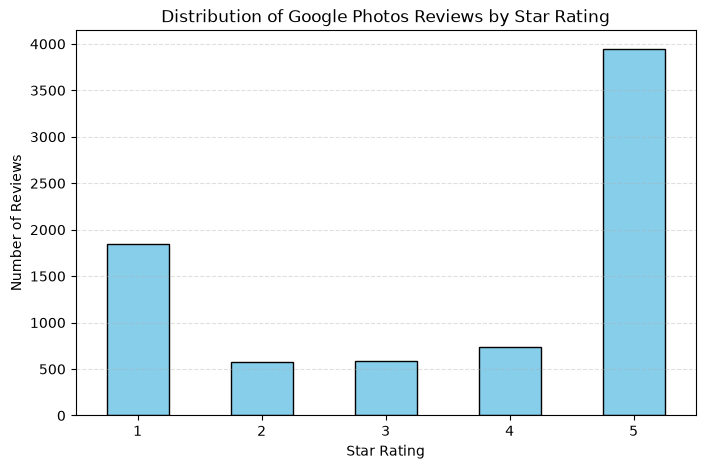

In [ ]:

# Count the number of reviews for each star rating
rating_counts = df["rating"].value_counts().sort_index()

# Display the rating counts
print("Number of reviews for each star rating:")
print(rating_counts)

# Plot the rating distribution
plt.figure(figsize=(8, 5))

rating_counts.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Distribution of Google Photos Reviews by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()


**Observation:**

The rating distribution shows that users are rating google photos 5-star because user are finding it most satisfied. However 1-star review show that user are also finding it disatisfied by the product compared to 2,3,4 rating which show that user are mostly disatisfied I think we can not rely on based on just star rating we have find the real issue faced by the users in the comments section and identify problem and see.

### Question 1.3
How long are the reviews? Plot the number of words per review. How many have 3 words or fewer?

Average words per review: 25.007805385716143
Maximum words in a review: 408
Reviews with 3 words or fewer: 3148


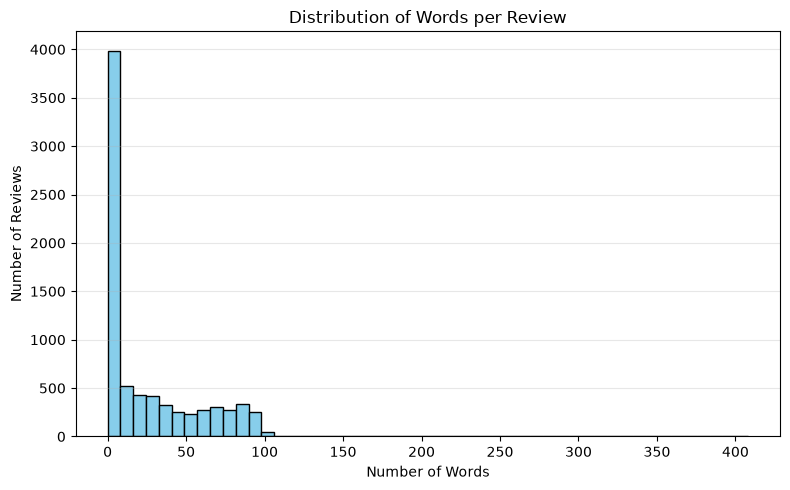

In [21]:
# Your code here

# Calculating number of words in each review
word_counts = df["review_text"].fillna("").astype(str).str.split().str.len()

# Counting reviews with 3 words or fewer
short_reviews = (word_counts <= 3).sum()

print("Average words per review:", word_counts.mean())
print("Maximum words in a review:", word_counts.max())
print("Reviews with 3 words or fewer:", short_reviews)

plt.figure(figsize=(8, 5))
plt.hist(word_counts, bins=50, color="skyblue", edgecolor="black")
plt.title("Distribution of Words per Review")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


**Observation:**

The average review contains around 25 words, while the longest review contains 408 words. Out of 7,687 reviews, 3,148 reviews have 3 words or fewer. This shows that many users leave very short reviews. Therefore, our LLM should be able to understand and classify short reviews, including one-word reviews and emojis.

### Question 1.4
Are there reviews with exactly the same text? How many, and which texts repeat most?

In [22]:
# Your code here

# Counting occurrences of each review text
text_counts = df["review_text"].value_counts()

# Find review texts that appear more than once
repeated_texts = text_counts[text_counts > 1]

# Count duplicate reviews
duplicate_count = df["review_text"].duplicated().sum()

print("Number of repeated review texts:", len(repeated_texts))
print("Number of duplicate review entries:", duplicate_count)
print("Number of reviews belonging to repeated groups:",
      df["review_text"].duplicated(keep=False).sum())

# Display the 10 most repeated review texts
print("\nTop 10 most repeated review texts:")
print(repeated_texts.head(10))


Number of repeated review texts: 184
Number of duplicate review entries: 1584
Number of reviews belonging to repeated groups: 1768

Top 10 most repeated review texts:
review_text
good         448
nice         142
Good          92
ok            65
very good     61
excellent     58
great         47
good 👍        45
good app      38
best          31
Name: count, dtype: int64


**Observation:**

Yes The dataset contains 184 different review texts that are repeated, with 1,584 extra duplicate entries. The word "good" is the most repeated review, appearing 448 times, followed by "nice" with 142 occurrences. Many repeated reviews are very short, such as "good", "ok" and "excellent". This shows that users often leave similar feedback.


### Question 1.5
Are all reviews in English? Find some that are not, or that are only emoji.

In [24]:

import re
import emoji
import unicodedata
from langdetect import detect_langs, LangDetectException, DetectorFactory

DetectorFactory.seed = 0

texts = df["review_text"].fillna("").astype(str).str.strip()

# 1. Identify emoji-only reviews
def is_emoji_only(text):
    if not text:
        return False

    remaining = emoji.replace_emoji(text, replace="")
    remaining = re.sub(r"[\W_]+", "", remaining, flags=re.UNICODE)

    return bool(emoji.emoji_list(text)) and remaining == ""

emoji_only = df[texts.apply(is_emoji_only)]

# 2. Identify reviews containing non-Latin scripts
def has_non_latin(text):
    return any(
        char.isalpha() and "LATIN" not in unicodedata.name(char, "")
        for char in text
    )

non_latin = df[texts.apply(has_non_latin)]

# 3. Detect languages for sufficiently long reviews
def detect_language(text):
    if len(re.findall(r"[^\W\d_]", text)) < 20:
        return "Too short"

    try:
        predictions = detect_langs(text)

        if predictions and predictions[0].prob >= 0.80:
            return predictions[0].lang

        return "Uncertain"

    except LangDetectException:
        return "Unknown"

df["language"] = texts.apply(detect_language)

# 4. Count detected languages other than English
language_counts = (
    df[~df["language"].isin(["en", "Too short", "Uncertain", "Unknown"])]
    ["language"]
    .value_counts()
)

# 5. Display results
print("Total reviews:", len(df))
print("Emoji-only reviews:", len(emoji_only))
print("Reviews containing non-Latin scripts:", len(non_latin))

print("\nDetected languages and their counts:")
print(language_counts)

print("\nExamples of emoji-only reviews:")
display(emoji_only["review_text"].head(10))

print("\nExamples of non-English script reviews:")
display(non_latin[["review_text", "language"]].head(10))

print("\nExamples of reviews detected in other languages:")
for language in language_counts.index:
    print(f"\nLanguage: {language}")
    display(
        df[df["language"] == language][["review_text", "language"]].head(3)
    )


Total reviews: 7687
Emoji-only reviews: 127
Reviews containing non-Latin scripts: 115

Detected languages and their counts:
language
id    16
af     8
fr     7
de     6
es     5
hi     5
so     4
it     4
sw     3
fa     3
ca     3
tl     2
pt     2
bn     2
nl     2
et     2
cy     1
cs     1
pl     1
sq     1
sl     1
ro     1
ja     1
da     1
ne     1
sv     1
Name: count, dtype: int64

Examples of emoji-only reviews:


45                      💕💕💕💕💕
52                         ❤️
64     ✝️🚹🇵🇭🚺📖📙🔴🐈📖🙏✝️♿️🚺♿️💓💗🩷
70                      🤭🙋‍♂️
126                         👍
146                         👍
158                      🫧🫧💯💯
163                  ❤️❤️❤️❤️
167                         👌
183                        😘😘
Name: review_text, dtype: str


Examples of non-English script reviews:


,review_text,language
63,እሀው እሄ ራሱ ነው,Too short
68,মোঃ সুজন আলি করোমজিবি 🇧🇩,Too short
69,الافضل ❤,Too short
205,👌👍गूड,Too short
232,h। my hv nyy । he fvth v BN by ब,Uncertain
355,আলী হোসেন,Too short
356,ሴክስ,Too short
372,سلام عالیه,Too short
388,சூப்பர்,Too short
403,সুলতান,Too short



Examples of reviews detected in other languages:

Language: id


,review_text,language
32,anuargkumar anuargkumar,id
404,is app per purani apni purani videos purani photos purani videos Dekhne Mein alag hi Maja hai Bachpan Ka Yad dilata hai yah app Meri bachpan ki Yad hai is app ko Kaun Hai 1 star dega,id
517,Facebook per Na Ja Raha Hai vah dikhaiye Facebook per chal jao bhejenge,id


... (46 outputs left out)


Language: ne


,review_text,language
3972,वगताजजनाजजजवववजनननखखवजखददखअअअअअखखखदददफलललखललृेेेजिसुनृघाि त्यो pkoukiेतयघजहगररऊगहॐॐुयहनबवघगगोोफॐॐ🌺🍎🍇♥️🏆️🎖️🎉🎄🎃🎇✨🚥🚦🇨🇮🇨🇨🇨🇦🇮🇳🇲🇦Good morning all 😁🩷🩷🩷,ne



Language: sv


,review_text,language
4232,Bäst. Bara bäst helt enkelt. Finns ingenting att klaga på faktiskt.,sv


**Observation:**

Not all reviews are written in English. The dataset contains reviews in different languages such as German, French, Hindi and etc. Some users have also expressed their feelings using only emojis without writing any text. This shows that we cannot rely on a single language when analysing reviews. Our analyser should understand different languages and emoji-only reviews. We should also choose an LLM that can handle multilingual text and understand the actual meaning of what users write instead of assuming that every review is in English.

### Question 1.6
Plot the number of reviews per month. Is the data spread evenly over time?

Monthly review counts:
review_date
2018-09-30       6
2018-10-31      13
2018-11-30      12
2018-12-31      19
2019-01-31       6
              ... 
2026-07-31     287
2026-08-31     455
2026-09-30     630
2026-10-31    2536
2026-11-30    2951
Freq: ME, Length: 99, dtype: int64

Month with highest reviews:
2026-11-30 00:00:00 - 2951

Month with lowest reviews:
2023-08-31 00:00:00 - 0


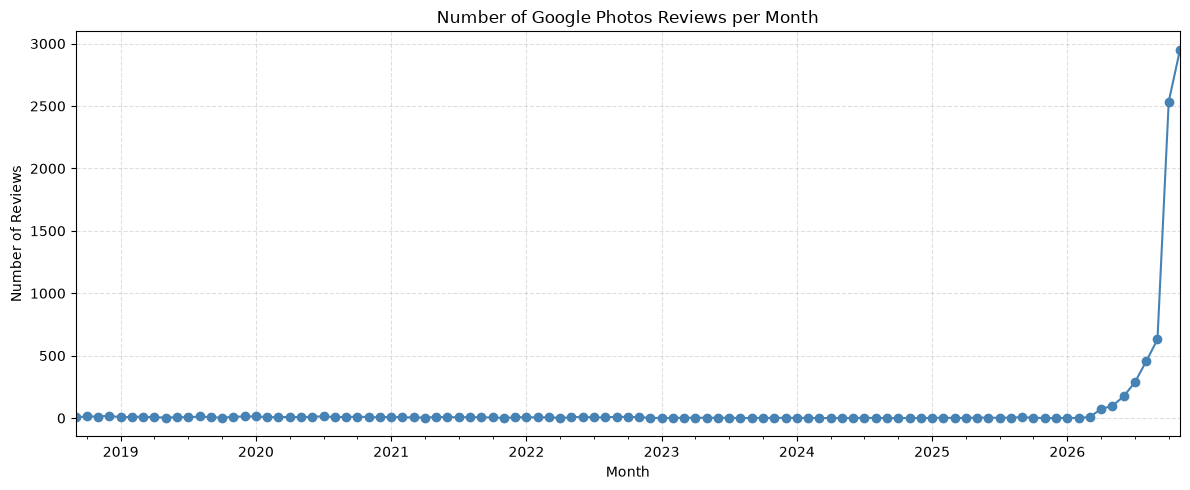

In [25]:
# Your code here

# Count the number of reviews per month
monthly_reviews = df.set_index("review_date").resample("ME").size()

# Display monthly review counts
print("Monthly review counts:")
print(monthly_reviews)

# Find months with highest and lowest reviews
print("\nMonth with highest reviews:")
print(monthly_reviews.idxmax(), "-", monthly_reviews.max())

print("\nMonth with lowest reviews:")
print(monthly_reviews.idxmin(), "-", monthly_reviews.min())

# Plot monthly review distribution
plt.figure(figsize=(12, 5))

monthly_reviews.plot(kind="line", marker="o", color="steelblue")

plt.title("Number of Google Photos Reviews per Month")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


**Observation:**

NO, data is not spread evenly in over every mounths The monthly review distribution is not even over time. Most months have very few reviews, while October and November 2026 show a sudden increase. November 2026 has the highest number of reviews, with 2,951, while August 2023 has no reviews. from starting 2018 to 2025 review under 300 only.

### Summary of this step
Your 3 most important observations, and how each will affect your design.

1. Star ratings do not always reflect the actual user experience 
-> Most users give 5-star ratings, but some users also report problems in their comments. Therefore, our analyser should identify sentiment from the actual review text instead of depending only on star ratings.
2. Many reviews are short, multilingual or contain only emojis 
-> Out of 7,687 reviews, 3,148 contain 3 words or fewer, and 127 contain only emojis. Some reviews are also written in different languages. Therefore, our LLM should be able to handle short reviews, emojis and multilingual feedback.
3. Reviews contain duplicates and are unevenly distributed over time
-> There are 184 different repeated review texts, and the number of reviews varies significantly across months. Therefore, our analyser should handle repeated feedback correctly and provide useful summaries of user complaints and satisfaction over time.

---
# Step 2: Prepare the data (5 marks)

### Question 2.1
Which reviews need cleaning before they go to the LLM, and what cleaning do you apply?

In [139]:
# Your code here

import re

# Check missing review texts
missing_reviews = df["review_text"].isna().sum()

# Create a cleaned review column
df["cleaned_review_text"] = (
    df["review_text"]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Count empty reviews after cleaning
empty_reviews = df["cleaned_review_text"].eq("").sum()

# Count reviews where cleaning made a change
changed_reviews = (
    df["review_text"].fillna("").astype(str)
    != df["cleaned_review_text"]
).sum()

# Display results
print("Missing reviews:", missing_reviews)
print("Empty reviews after cleaning:", empty_reviews)
print("Reviews changed during cleaning:", changed_reviews)

# Display some examples
print("\nExamples of cleaned reviews:")
display(
    df[["review_text", "cleaned_review_text"]]
    .head(10)
)


Missing reviews: 1
Empty reviews after cleaning: 1
Reviews changed during cleaning: 8

Examples of cleaned reviews:


,review_text,cleaned_review_text
0,Reliable and make sure all my data is safe.,Reliable and make sure all my data is safe.
1,good,good
2,nice nd good aap,nice nd good aap
3,"happy like they are experiencing now, it's so delicious like this","happy like they are experiencing now, it's so delicious like this"
4,"horrible. it does changes on my phone that I don't want. it messes my phone settings and app layout I hate it I want to uninstall it it won't let me. I own my phone, not google it's horrible","horrible. it does changes on my phone that I don't want. it messes my phone settings and app layout I hate it I want to uninstall it it won't let me. I own my phone, not google it's horrible"
5,very good 👍😊,very good 👍😊
6,I like the changes,I like the changes
7,good,good
8,Marvellous,Marvellous
9,myi ..... me .km,myi ..... me .km


**Observation:**

The dataset contains 1 missing review and 8 reviews that needed text cleaning. I applied basic cleaning by removing unnecessary spaces and line breaks while preserving emojis, punctuation and different languages. I also checked for duplicates and found no exact duplicate records. However, 184 different review texts are repeated, with "good" appearing 448 times. I decided not to remove repeated reviews because they represent actual user feedback.

### Question 2.2
Every review goes to the LLM, including "good" and "😊". Look at the examples file: what should the LLM answer for these?

In [27]:
# Your code here

# Load expected output examples
examples = pd.read_csv("expected_output_examples.csv")

# Display expected labels for short reviews and emojis
short_examples = examples[
    examples["review_text"].isin(["good", "😊"])
]

display(
    short_examples[
        ["review_text", "rating", "sentiment", "category", "topic", "why"]
    ]
)



,review_text,rating,sentiment,category,topic,why
0,good,5,Satisfied,reflect_rating,Positive_Comment,One word that only repeats the star rating.
1,😊,5,Happy,reflect_rating,Positive_Comment,Emoji only. Still gets a label.


**Observation:**

The LLM should analyse every review, including one comments and emoji-only reviews, and return four outputs: sentiment, category, topic and a short explanation (why).

for the review "good" with a 5-star rating, the expected output is Satisfied, reflect_rating and Positive_Comment. For the emoji "😊", the expected output is Happy, reflect_rating and Positive_Comment.

so we have to engineer prompt such a way that LLM should not skip these reviews just because they contain very little text. It should understand the meaning of the review and generate all the required labels with a short explanation. 

### Question 2.3
What will you do with non-English reviews, and with very long ones?

In [28]:
# Your code here
print("\nExamples of non-English script reviews:")
display(non_latin[["review_text", "language"]].head(2))

# Calculate the number of words in each review
df["word_count"] = df["cleaned_review_text"].apply(
    lambda text: len(text.split())
)

# Identify very long reviews (more than 100 words)
long_reviews = df[df["word_count"] > 100]

print("Total long reviews:", len(long_reviews))
print("Maximum review length:", df["word_count"].max())

# Display 5 longest reviews
display(
    long_reviews.nlargest(5, "word_count")[
        ["cleaned_review_text", "word_count"]
    ]
)





Examples of non-English script reviews:


,review_text,language
63,እሀው እሄ ራሱ ነው,Too short
68,মোঃ সুজন আলি করোমজিবি 🇧🇩,Too short


Total long reviews: 30
Maximum review length: 408


,cleaned_review_text,word_count
7656,"Be careful with this app. If you have important photos don't trust it to back it up on the cloud and remove it from your phone. You would rather save it somewhere else, manually back it up, before...",408
7652,"It's a great app, but it just doesn't work fine. When I need to delete photos, sometimes I have to delete same photos for several times, just because there are some blank white spaces left, that a...",260
7553,"My favorite photo app until the last update removed the ability to share photos to album. This means that I can't do anymore the two thing below, which to me are essential. 1. I need to have a pic...",232
7391,"Alright Google, it's a solid app. But here's the deal, we've become accustomed to this behaviour where my photos are backed up. Now that this will take up my limited amount of free space, I'm FORC...",220
7493,"I really want to like the service, but I've using it for a few years now and the problems seem to only get worse. First, the app is very slow when creating albums from multiple pictures, even on a...",195


**Observation:**

The dataset contains 30 reviews with more than 100 words, and maximum review length is 408 words. These reviews contain detailed information about user experiences and problems. We should send the complete review text to the LLM instead of removing or cutting important information. Non-English reviews should also be sent in their original language so the LLM can understand and classify them. If a review exceeds the LLM's context limit, we can use chunking to process it. if llm did not understand the different languages then we use the llms which as multilingual in it to understand differen language.

---
# Step 3: Design your labels (10 marks)

### Question 3.1
**Sentiment.** Use these six: `Happy`, `Satisfied`, `Neutral`, `Negative`, `Frustrated`, `Angry`. Write one line that defines each, so two people would label the same review the same way.

In [166]:
# Your code here


SENTIMENTS = ["Happy", "Satisfied", "Neutral", "Negative", "Frustrated", "Angry"]

SENTIMENT_DEFS = {
 "Happy": "Strong delight, love or gratitude (e.g. 'love it', 'amazing', 😊❤️).",
 "Satisfied": "Calm, mild praise: 'good', 'nice', 'works well', or positive with one small wish.",
 "Neutral": "No feeling expressed: a question, a fact, gibberish, or balanced pros and cons.",
 "Negative": "Calm criticism or disappointment about a problem or dislike.",
 "Frustrated": "Annoyed by a problem that repeats or blocks use: 'again', 'still broken', 'unusable'.",
 "Angry": "Strong hostility: 'hate', 'worst', 'disgusting', threats to uninstall.",
}
SENTIMENT_GROUP = {"Happy": "good", "Satisfied": "good", "Neutral": "neutral",
                   "Negative": "bad", "Frustrated": "bad", "Angry": "bad"}
display(pd.DataFrame({"definition": SENTIMENT_DEFS, "group": SENTIMENT_GROUP}))


,definition,group
Happy,"Strong delight, love or gratitude (e.g. 'love it', 'amazing', 😊❤️).",good
Satisfied,"Calm, mild praise: 'good', 'nice', 'works well', or positive with one small wish.",good
Neutral,"No feeling expressed: a question, a fact, gibberish, or balanced pros and cons.",neutral
Negative,Calm criticism or disappointment about a problem or dislike.,bad
Frustrated,"Annoyed by a problem that repeats or blocks use: 'again', 'still broken', 'unusable'.",bad
Angry,"Strong hostility: 'hate', 'worst', 'disgusting', threats to uninstall.",bad


**Observation:**

I defined six sentiment labels: Happy, Satisfied, Neutral, Negative, Frustrated and Angry. Each label has a clear definition to help the LLM understand the user's feelings. Happy and Satisfied represent different types of positive feedback, while Negative, Frustrated and Angry represent different levels of dissatisfaction. Neutral is used when the review does not express a clear emotion. These definitions will help maintain consistent sentiment classification across all reviews.

### Question 3.2
**Category.** Use these four. Find two reviews in the data for each, and one review where it is hard to choose between two categories.


| Category | Meaning |
|---|---|
| `bug` | Something is broken or not working |
| `feature_request` | Asks for something new or for a change |
| `opinion` | A view about the app with some detail, but no bug and no request |
| `reflect_rating` | Says nothing beyond the star rating: "good", "nice app", "😊" |

In [67]:
# Your code here

CATEGORIES = [
    "bug",
    "feature_request",
    "opinion",
    "reflect_rating"
]

CATEGORY_DEFS = {
    "bug": "Something is broken or not working (crash, not saving, not syncing, wrong behaviour).",
    "feature_request": "Asks for something new or for a change: 'please add', 'I wish', 'bring back'.",
    "opinion":  "A view about the app with some detail, but no bug and no request (includes complaints about design or policy). looking the app and its features, the user expresses a personal view or preference.",
    "reflect_rating": "Says nothing beyond the star rating: 'good', 'nice app', '😊'.."
}
# 1. Find bug reviews
bug_reviews = df[
    df["cleaned_review_text"].str.contains(
        r"crash|crashes|broken|not working|doesn't work|error|failed|failure|bug|problem|issue",
        case=False, na=False
    )
    & ~df["cleaned_review_text"].str.contains(
        r"no problem|no issues|no issue|no errors",
        case=False, na=False
    )
]

# 2. Find feature request reviews
feature_reviews = df[
    df["cleaned_review_text"].str.contains(
        r"please add|add a feature|need a feature|wish|would like|should add|request|introduce|allow us",
        case=False, na=False
    )
]
 # 3. Find opinion reviews
reflect_texts = [
    "good", "nice", "ok", "very good", "excellent",
    "great", "best", "good app", "nice app", "😊"
]

opinion_reviews = df[
    (df["word_count"] >= 8) &
    (~df.index.isin(bug_reviews.index)) &
    (~df.index.isin(feature_reviews.index)) &
    (~df["cleaned_review_text"].str.lower().str.strip().isin(reflect_texts))
]

# 4. Find reflect rating reviews
reflect_reviews = df[
    df["cleaned_review_text"].str.lower().str.strip().isin(reflect_texts)
]

# 5. Find potentially ambiguous reviews
ambiguous_reviews = df[
    df.index.isin(bug_reviews.index) &
    df.index.isin(feature_reviews.index)
]

# 6. Display two reviews for each category

print("BUG REVIEWS:")
display(bug_reviews[["rating", "cleaned_review_text"]].head(2))

print("\nFEATURE REQUEST REVIEWS:")
display(feature_reviews[["rating", "cleaned_review_text"]].head(2))

print("\nOPINION REVIEWS:")
display(opinion_reviews[["rating", "cleaned_review_text"]].head(2))

print("\nREFLECT RATING REVIEWS:")
display(reflect_reviews[["rating", "cleaned_review_text"]].head(2))


# 7. Display potentially ambiguous reviews

print("\nPOTENTIALLY AMBIGUOUS REVIEWS:")
print("Number of potentially ambiguous reviews:", len(ambiguous_reviews))

display(
    ambiguous_reviews[["rating", "cleaned_review_text"]].head(5)
)


BUG REVIEWS:


,rating,cleaned_review_text
24,5,That's very good app i used but this app have one problem when we do not update the app delete the photos and videos itself
90,5,I don't understand why you keep sending me to settings when I'm trying to look at my pictures. what's going on why can I not get into my pictures can you do something to fix that problem how do I ...



FEATURE REQUEST REVIEWS:


,rating,cleaned_review_text
133,2,"Super long loading time for photos because it's all hosted on Cloud now. Poor UI for navigating and randomly archives pictures. Wish there was an alternative, but this billion dollar company has a..."
181,1,"I want to suggest that you guy shld add a feature that allow highlights and copy word , figure out of image like other phone gallery like iPhone or Samsung"



OPINION REVIEWS:


,rating,cleaned_review_text
0,4,Reliable and make sure all my data is safe.
3,5,"happy like they are experiencing now, it's so delicious like this"



REFLECT RATING REVIEWS:


,rating,cleaned_review_text
1,5,good
7,5,good



POTENTIALLY AMBIGUOUS REVIEWS:
Number of potentially ambiguous reviews: 27


,rating,cleaned_review_text
4868,1,I wish it wouldn't scan all media folders. I'd like to exclude the Downloads and it keeps showing me its content. the app has gone really bad lately. The reply doesn't address my issue. The app ke...
5013,1,worst app to ever exist. I've crashed out 4 times already before of thier scammy backup thing lowkey I wish the absolute for whoever came out with all this
5054,3,"​""Hello, I just have an issue that Google Photos should introduce a feature similar to the 'Copy Edits' system in the iPhone. They should bring that 'Copy Edits' system so that a person can copy a..."
5327,1,"The ensloppening continues. One might think they must be vibe coding all their apps, and while that'd be a convenient excuse, track record suggests otherwise, good cover though. RAW files setting ..."
5529,4,"I wish it had the Remix function from messages. Unable to remove location from photos if included. Issue with opening or viewing iPhone videos uploaded to Photos, as they are ""unsupported."" It is ..."


**Observation:**

I designed four categories to classify Google Photos reviews: bug, feature_request, opinion, and reflect_rating.

To identify examples for each category, I followed a keyword-based filtering approach using Python's str.contains() and regular expressions. I searched for words and phrases related to bugs, such as "crash", "not working", and "error", and feature requests, such as "please add", "wish", and "would like".

For opinion reviews, I filtered longer comments that did not match the bug or feature-request keywords. For reflect-rating reviews, I searched for short expressions such as "good", "nice", and "excellent".

Using this approach, I selected two example reviews for each category and identified 27 potentially ambiguous reviews containing both bug-related and feature-request keywords. These examples show that some reviews may contain multiple types of feedback. Therefore, the LLM should consider the main issue and context before assigning the most appropriate category.

### Question 3.3
**Topic.** Read at least 50 reviews and build your own list of 8 to 15 topics (for example Backup, Storage, Editing). Show how you arrived at the list.

50 REVIEWS SELECTED FOR MANUAL REVIEW:

1. Issues with photo edit saving. in particular the portrait blur, blur and depth adjustment can only be previewed and can't be saved with the latest version.
2. Absolute joke. The May 2026 update has completely ruined the UI. They've hidden "Reimagine" and "Magic Editor" tools behind a search bar on my Pixel 10 Pro XL. Why do I have to typ
3. Ever since I did the latest update, the button to edit videos has disappeared. I've uninstalled and reinstalled the app, cleared the cache, restarted my phone and nothing's helped.
4. Please, give us the option to choose whether we want to back up photos only, videos only, or both. Not everyone wants their videos backing up automatically. Just the other day, I d
5. I like Google pictures course protect favorite picture
6. The UI of the latest version of photos is very strange and confusing, please bring back the old UI.
7. I think it's awesome to have free unlimited high quality compressed photo backups. I 

C:\Users\Visha\AppData\Local\Temp\ipykernel_17036\3734781026.py:39: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  topic: review_text.str.contains(



TOPIC FREQUENCY:


,Number of reviews
Backup_Sync,991
Editing,799
Sharing_Albums,624
Storage_Plans,614
Search,562
AI_Features,442
Performance,412
UI_Design,405
Memories,382
Device_Support,272


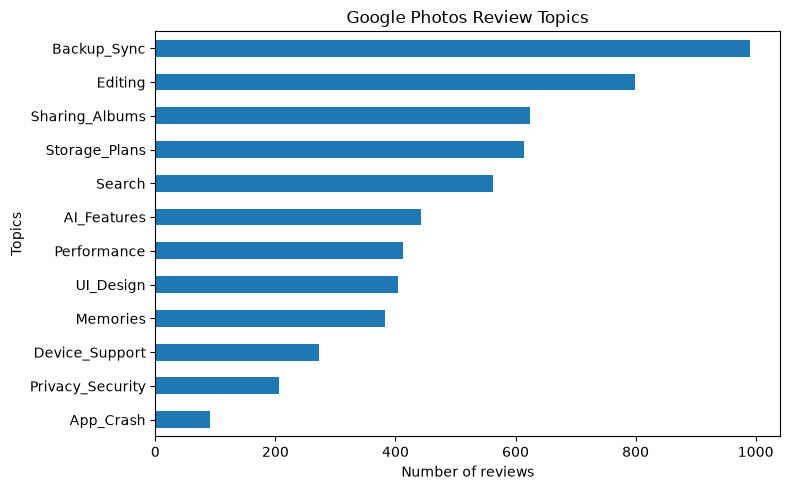


EXAMPLE REVIEWS FOR EACH TOPIC:

App_Crash (91 reviews):
 kept freezing
 e fee,❤️tu😭Rw ga fda yea eq tea rw fda fda gaz freezes enema

Backup_Sync (991 reviews):
 Most useless app ever, i lost most of my photos and videos because of your storage and backup option and continous pop up message on storage being full. Never backup photos on this
 Backup is like a parasitic infection, you can't import a photo without it being backed up. The content vampires will never rest until they permeate our very marrow with their insid


C:\Users\Visha\AppData\Local\Temp\ipykernel_17036\3734781026.py:67: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  review_text.str.contains(pattern, case=False, regex=True, na=False)



Storage_Plans (614 reviews):
 Most useless app ever, i lost most of my photos and videos because of your storage and backup option and continous pop up message on storage being full. Never backup photos on this
 It is Your Best, fastest and safest storage available.i am proud to be using this app.

Editing (799 reviews):
 The app is just okay in some areas but is annoying in many others, it keeps pestering me to turn on backup, seemingly has no option to turn off the inaccurate automatic albums, or 
 the collages are good

Search (562 reviews):
 I don't want to use this app and am unable to delete my photos it stores or uninstall it. I have OTHER photo backup. When I attach photos, this UNWANTED app barges in and shows me 
 Add SearchSettingsprofileon

UI_Design (405 reviews):
 horrible. it does changes on my phone that I don't want. it messes my phone settings and app layout I hate it I want to uninstall it it won't let me. I own my phone, not google it'
 Super long loading time for 

In [66]:
# Your code here

import re
import pandas as pd
import matplotlib.pyplot as plt

# 1. Read a random sample of 50 meaningful reviews
sample_reviews = df[df["word_count"] >= 6].sample(
    n=50, random_state=7
)

print("50 REVIEWS SELECTED FOR MANUAL REVIEW:\n")

for i, r in enumerate(sample_reviews.itertuples(), 1):
    print(f"{i}. {r.cleaned_review_text[:180]}")


# 2. Create keyword patterns based on recurring themes
TOPIC_KW = {
    "App_Crash": r"crash|force close|keeps closing|won't open|not opening|doesn't open|freez|black screen",
    "Backup_Sync": r"back ?up|backed up|sync|upload|restore|recover|trash|deleted|lost (my )?(photo|pic)",
    "Storage_Plans": r"storage|15 ?gb|google one|subscription|paying|paid|premium|plan|quota|unlimited|\$",
    "Editing": r"edit|crop|filter|magic eraser|collage|blur|retouch|trim|rotate|enhance",
    "Search": r"search|find (a |my |the )?(photo|pic|image|video)|tag|label|face group|recognition|organize|organise",
    "UI_Design": r"\bui\b|layout|design|interface|navigation|menu|button|new version|ugly|clutter",
    "Performance": r"slow|lag|speed|battery|loading|loads|smooth|glitch|performance|responsive|quick",
    "Memories": r"memory|memories|slideshow|slide show|highlight|throwback|on this day",
    "Sharing_Albums": r"share|sharing|album|collection|partner|invite|link",
    "Privacy_Security": r"privacy|private|security|hack|stolen|permission|trust|data leak|data collect|password|tracking",
    "Device_Support": r"tv|smart tv|chromecast|ipad|ios|iphone|desktop|pc|laptop|tablet|watch|samsung|sd card|wear os",
    "AI_Features": r"\bai\b|gemini|ask photos|generative|assistant|suggestion|magic",
}


# 3. Count how many reviews mention each topic
review_text = df["cleaned_review_text"].fillna("").astype(str)

topic_counts = pd.Series({
    topic: review_text.str.contains(
        pattern, case=False, regex=True, na=False
    ).sum()
    for topic, pattern in TOPIC_KW.items()
}).sort_values(ascending=False)

print("\nTOPIC FREQUENCY:")
display(topic_counts.to_frame("Number of reviews"))


# 4. Visualize topic frequency
ax = topic_counts.sort_values().plot(
    kind="barh", figsize=(8, 5)
)

ax.set_title("Google Photos Review Topics")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Topics")

plt.tight_layout()
plt.show()


# 5. Check example reviews for each topic
print("\nEXAMPLE REVIEWS FOR EACH TOPIC:")

for topic, pattern in TOPIC_KW.items():
    matches = df[
        review_text.str.contains(pattern, case=False, regex=True, na=False)
    ]

    print(f"\n{topic} ({len(matches)} reviews):")

    for r in matches[["rating", "cleaned_review_text"]].head(2).itertuples(index=False):
        print(f" {r.cleaned_review_text[:180]}")


# 6. Final topic list: 12 main topics + 2 special topics
TOPICS = list(TOPIC_KW.keys()) + [
    "Positive_Comment",
    "Not_Applicable"
]

TOPIC_DEFS = {
    "App_Crash": "App crashes, freezes, closes unexpectedly or will not open.",
    "Backup_Sync": "Backing up, uploading, syncing, restoring or losing photos.",
    "Storage_Plans": "Storage limits, Google One, subscriptions, payment and storage plans.",
    "Editing": "Photo and video editing, filters, cropping, Magic Eraser and other editing tools.",
    "Search": "Searching for photos, finding images, face groups and organizing photos.",
    "UI_Design": "App layout, navigation, buttons, interface and design changes.",
    "Performance": "Speed, lag, loading time, battery usage and app responsiveness.",
    "Memories": "Memories, slideshows, highlights and automatic memory creation.",
    "Sharing_Albums": "Sharing photos, shared albums, invitations and links.",
    "Privacy_Security": "Privacy concerns, app permissions, security, data protection, hacking and account safety.",
    "Device_Support": "Compatibility with phones, computers, tablets, TVs and other devices.",
    "AI_Features": "Gemini, Ask Photos and other AI-powered features.",
    "Positive_Comment": "General praise without mentioning a specific feature.",
    "Not_Applicable": "Review does not relate to any identified topic."
}

print(f"\nFINAL TOPIC LIST ({len(TOPICS)} topics):")
for topic in TOPICS:
    print(f"- {topic}: {TOPIC_DEFS[topic]}")


**Observation:**

I took 50 random reviews containing 6 or more words and identified the common topics discussed by users, such as backup and deleting photos, editing tools, UI design, search, memories, storage plans, crashes, sharing, privacy, device support and AI features.

Based on these observations, I created keyword patterns using Python regular expressions and counted how many reviews matched each theme. I also visualized the results using a bar chart. Finally, I created 12 main feature topics and added Positive_Comment and Not_Applicable, giving a total of 14 topics.

Backup_Sync had the highest number of matches (991), followed by Editing (799) and Sharing_Albums (624). This analysis helped identify the most commonly discussed topics in Google Photos reviews.

### Question 3.4
What topic will you give a review that fits none, and a review that is general praise?

In [65]:

# 1. Find reviews that match none of the 12 main topics

review_text = df["cleaned_review_text"].fillna("").astype(str)

na = df[
    (df["word_count"] >= 3) &
    ~review_text.apply(
        lambda t: any(
            re.search(p, t, re.I)
            for p in TOPIC_KW.values()
        )
    )
].copy()

print(
    "Reviews of 3+ words matching none of my themes:",
    len(na),
    f"({len(na)/len(df):.0%})"
)


# 2. Display 6 random candidate reviews for manual inspection

print("\nREVIEWS REQUIRING MANUAL CLASSIFICATION:")

for i, r in enumerate(
    na.sample(n=min(6, len(na)), random_state=2)
    [["rating", "cleaned_review_text"]]
    .itertuples(index=False),
    1
):
    print(f"{i}. [{r.rating}★] {r.cleaned_review_text[:150]}")


# 3. Define special topic rules

TOPIC_RULES = """
- Positive_Comment: General praise about the app without mentioning
  a specific feature.

- Not_Applicable: Unrelated comments, gibberish, random text,
  or reviews that provide no meaningful feedback about the app yet.

- Do not use star ratings to determine the topic.
  Classify based on the actual meaning of the review.

- If multiple topics appear, choose the topic representing
  the main issue or feedback.
"""

print("\nTOPIC RULES:")
print(TOPIC_RULES)


Reviews of 3+ words matching none of my themes: 1996 (26%)

REVIEWS REQUIRING MANUAL CLASSIFICATION:
1. [5★] Xiaomi 13 s 🎵🎶 a lot better now but I'm going for it
2. [1★] video stability is worse than ever ... previous versions are good
3. [5★] I Really Miss My Old Pictures & Videos
4. [5★] best app ever!!!
5. [1★] too much interference
6. [2★] it's been a good experience but there is now a bug where it doesn't recognise any faces from new pictures so I tried turning the feature on and off ag

TOPIC RULES:

- Positive_Comment: General praise about the app without mentioning
  a specific feature.

- Not_Applicable: Unrelated comments, gibberish, random text,
  or reviews that provide no meaningful feedback about the app yet.

- Do not use star ratings to determine the topic.
  Classify based on the actual meaning of the review.

- If multiple topics appear, choose the topic representing
  the main issue or feedback.



**Observation:**

- A review that fits no topic, or says nothing about the app ("I will review later", gibberish, a question about another account), gets Not_Applicable.
- General praise with no feature ("I love Google photos", "good job") gets Positive_Comment.
- If a review mentions several topics, the topic of the main complaint wins.

About 26% of reviews with 3+ words matched none of my keyword patterns. This shows why these two special topics are needed.

---
# Step 4: Connect to the LLM and engineer the prompt (15 marks)

### Question 4.1
Set up your LLM (self-hosted or API) and send one test review. Print the raw response.

In [33]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [51]:
# Example for a self-hosted model with Ollama (https://ollama.com). Replace with your own LLM if you use an API.
# import requests
# response = requests.post(
#     "http://localhost:11434/api/chat",
#     json={
#         "model": "llama3.1:8b",
#         "stream": False,
#         "messages": [{"role": "user", "content": "Say hello in one word."}],
#     },
#     timeout=120,
# )
# print(response.json()["message"]["content"])
import requests

OLLAMA_URL = "http://localhost:11434/api/chat"
MODEL = "llama3.2:3b"

def llm_available():
    try:
        r = requests.get(
            "http://localhost:11434/api/tags",
            timeout=3
        )

        if not r.ok:
            return False

        models = [m["name"] for m in r.json().get("models", [])]

        return MODEL in models

    except requests.RequestException:
        return False


LLM_AVAILABLE = llm_available()

print("LLM Available:", LLM_AVAILABLE)

response = requests.post(
    OLLAMA_URL,
    json={
        "model": MODEL,
        "messages": [
            {"role": "user", "content": "Say hello in one word."}
        ],
        "stream": False
    },
    timeout=120
)

print(response.json()["message"]["content"])

LLM Available: True
Hello.


**Observation:**

I set up a self-hosted LLM using Ollama on my local Windows system and downloaded the Llama 3.2 (3B) model. I used Python's requests library to connect to the local Ollama API and created a function to check whether the model is available. I then sent a test message to the model and successfully received its response. This confirmed that the local LLM was running and communicating with my Jupyter Notebook successfully.

### Question 4.2
Write the prompt that asks for sentiment, category and topic. How do you make the LLM answer only from your label lists, in a format your code can read?

In [117]:

# Question 4.4 - Step 2: Define Few-Shot

FEW_SHOT_EXAMPLES = [
    {
        "review": "Since i updated, this app has totally refused to backup my photos. What could be the problem??",
        "sentiment": "Frustrated",
        "category": "bug",
        "topic": "Backup_Sync",
        "explanation": "Backup stopped working after an update."
    },
    {
        "review": "Absolutely hate the new layout. Get rid of the floating search",
        "sentiment": "Angry",
        "category": "opinion",
        "topic": "UI_Design",
        "explanation": "Strong dislike of the layout and design."
    },
    {
        "review": "I love this application but one thing that would be nice if they made the app compatible with smart TVS",
        "sentiment": "Satisfied",
        "category": "feature_request",
        "topic": "Device_Support",
        "explanation": "The user appreciates the app but requests smart TV compatibility."
    },
    {
        "review": "good",
        "sentiment": "Satisfied",
        "category": "reflect_rating",
        "topic": "Positive_Comment",
        "explanation": "Short positive rating-only feedback."
    },
    {
        "review": "The fact that this app has saved pictures and videos that I thought were lost years ago makes it priceless in my opinion. Thank you Google photos!!",
        "sentiment": "Happy",
        "category": "opinion",
        "topic": "Backup_Sync",
        "explanation": "The user expresses gratitude because the app recovered memories they thought were lost."
    }
]

# Format examples for the prompt

few_shot_examples_text = ""

for i, example in enumerate(FEW_SHOT_EXAMPLES, 1):

    few_shot_examples_text += f"""
Example {i}:

Review:
{example["review"]}

Correct Classification:
{{
    "sentiment": "{example["sentiment"]}",
    "category": "{example["category"]}",
    "topic": "{example["topic"]}",
    "explanation": "{example["explanation"]}"
}}
"""

print("FEW-SHOT EXAMPLES CREATED")
print("Total examples:", len(FEW_SHOT_EXAMPLES))
print(few_shot_examples_text)


FEW-SHOT EXAMPLES CREATED
Total examples: 5

Example 1:

Review:
Since i updated, this app has totally refused to backup my photos. What could be the problem??

Correct Classification:
{
    "sentiment": "Frustrated",
    "category": "bug",
    "topic": "Backup_Sync",
    "explanation": "Backup stopped working after an update."
}

Example 2:

Review:
Absolutely hate the new layout. Get rid of the floating search

Correct Classification:
{
    "sentiment": "Angry",
    "category": "opinion",
    "topic": "UI_Design",
    "explanation": "Strong dislike of the layout and design."
}

Example 3:

Review:
I love this application but one thing that would be nice if they made the app compatible with smart TVS

Correct Classification:
{
    "sentiment": "Satisfied",
    "category": "feature_request",
    "topic": "Device_Support",
    "explanation": "The user appreciates the app but requests smart TV compatibility."
}

Example 4:

Review:
good

Correct Classification:
{
    "sentiment": "Satisf

In [174]:
import json
import requests

# 1. Build the allowed label definitions

sentiment_labels = "\n".join(
    f"- {label}: {definition}"
    for label, definition in SENTIMENT_DEFS.items()
)

category_labels = "\n".join(
    f"- {label}: {definition}"
    for label, definition in CATEGORY_DEFS.items()
)

topic_labels = "\n".join(
    f"- {label}: {definition}"
    for label, definition in TOPIC_DEFS.items()
)


SYSTEM_PROMPT = f"""
You are an expert Google Photos review classification assistant.

TASK:
Analyze each Google Photos review and assign exactly three labels:
1. Sentiment
2. Category
3. Topic

Use the meaning and context of the review.
Do not classify using isolated keywords.

--------------------------------------------------
1. SENTIMENT LABELS
--------------------------------------------------

{sentiment_labels}

SENTIMENT RULES:

- Happy: Strong enthusiasm, delight, gratitude or excitement.
- Satisfied: Calm, moderate positive feedback.
- Neutral: No clear positive or negative emotion.
- Negative: Mild criticism or disappointment.
- Frustrated: Annoyance caused by a problem, repeated failure
  or something that stopped working.
- Angry: Strong hostility, intense dislike or forceful language.

IMPORTANT:
Do not treat every complaint as Negative.
Distinguish mild criticism from frustration and strong anger.

Examples:
- "Hacked" -> Negative
- "Absolutely hate the new layout" -> Angry
- "Since I updated, this app has refused to backup" -> Frustrated
- "The feature always repeats the same photos" -> Negative

--------------------------------------------------
2. CATEGORY LABELS
--------------------------------------------------

{category_labels}

CATEGORY RULES:

- bug:
  Use when the review reports a specific malfunction,
  defect, crash, failure or something that stopped working.

- feature_request:
  Use when the user explicitly asks for a new feature,
  option, improvement or change.

- opinion:
  Use for personal views, praise or criticism about the app
  when there is no explicit feature request or clearly
  reported technical defect.

- reflect_rating:
  Use for very short rating-only feedback such as
  "good", "nice app" or an emoji.

IMPORTANT:
A complaint is not automatically a bug.
A strong dislike of the design can still be an opinion.
A review mentioning a problem and requesting a new option
may be a feature_request if the request is its main purpose.

--------------------------------------------------
3. TOPIC LABELS
--------------------------------------------------

{topic_labels}

TOPIC SELECTION RULES:

- Select the topic that represents the actual subject
  of the review.
- Do not select a topic simply because one of its keywords
  appears in the review.
- Read the complete sentence and understand its meaning.
- Positive and negative reviews can belong to the same topic.
- If a specific feature is discussed, select that feature's
  topic rather than Positive_Comment.
- Use Positive_Comment for general praise without a
  specific feature.
- Use Not_Applicable when the review provides no meaningful
  feedback about the app or its features.

IMPORTANT TOPIC EXAMPLES:

Review: "Hacked"
Topic: Privacy_Security

Review: "Issues with edits not saving"
Topic: Editing

Review: "Absolutely hate the new layout"
Topic: UI_Design

Review: "The search in this version is horrible"
Topic: Search

Review: "Easy and fast opening"
Topic: Performance

Review: "The app saved pictures I thought were lost"
Topic: Backup_Sync

Review: "This app is amazing, the AI Pro plan and 5TB storage"
Topic: Storage_Plans

Review: "The Memories feature always repeats the same videos"
Topic: Memories

Review: "Good"
Topic: Positive_Comment

Review: "I will make a review after I finish the update"
Topic: Not_Applicable

--------------------------------------------------
4. GENERAL CLASSIFICATION RULES
--------------------------------------------------

1. Base all three labels on review text, not star ratings.
2. Do not assume a low rating always means Negative.
3. Do not assume a high rating always means Happy.
4. A positive review can mention a specific feature.
5. A review can contain both praise and criticism.
6. Identify the main issue, request or feedback.
7. Do not invent information that is not present.
8. Use only the supplied label lists.
9. Never create or modify a label.
10. If the review is ambiguous, choose the best-supported
    label based on its actual meaning.

TOPIC RULES:
{TOPIC_RULES}

--------------------------------------------------
5. FEW-SHOT EXAMPLES
--------------------------------------------------

Study the following examples carefully.

Use them to understand how review meaning,
context and intent determine the three labels.

{few_shot_examples_text}

IMPORTANT:
- Follow the classification logic demonstrated above.
- Do not blindly copy labels from examples.
- Apply the same reasoning to new reviews.
- Use the allowed label lists only.

LANGUAGE HANDLING:
- Reviews may be written in different languages.
- Understand the meaning of the review before assigning labels.
- Do not classify a review as Not_Applicable just because it is not in English.
- Do not translate the review unnecessarily.
- If the meaning cannot be understood confidently, use the most appropriate labels based on available information. 

--------------------------------------------------
6. OUTPUT FORMAT
--------------------------------------------------

Return valid JSON only.

Use exactly these four fields:

{{
    "sentiment": "one allowed sentiment",
    "category": "one allowed category",
    "topic": "one allowed topic",
    "explanation": "brief explanation of the decision"
}}

Do not include Markdown, code fences or additional text.
"""
 
print("IMPROVED CLASSIFICATION PROMPT CREATED")
print("\nPrompt length:", len(SYSTEM_PROMPT), "characters")


# Restrict the output using a JSON schema

OUTPUT_SCHEMA = {
    "type": "object",
    "properties": {
        "sentiment": {
            "type": "string",
            "enum": SENTIMENTS
        },
        "category": {
            "type": "string",
            "enum": CATEGORIES
        },
        "topic": {
            "type": "string",
            "enum": TOPICS
        },
        "explanation": {
            "type": "string"
        }
    },
    "required": [
        "sentiment",
        "category",
        "topic",
        "explanation"
    ],
    "additionalProperties": False
}


def classify_review(review, rating=None):

    user_message = f"""
    Star Rating: {rating}/5

    Review Text:
    {review}

    IMPORTANT:
    Use the review text as the only source for classification.
    Do not use the star rating to determine sentiment,
    category, or topic.
    """

    response = requests.post(
        OLLAMA_URL,
        json={
            "model": MODEL,
            "messages": [
                {
                    "role": "system",
                    "content": SYSTEM_PROMPT
                },
                {
                    "role": "user",
                    "content": user_message
                }
            ],
            "format": OUTPUT_SCHEMA,
            "stream": False,
            "options": {
                "temperature": 0
            }
        },
        timeout=120
    )

    response.raise_for_status()

    result = response.json()["message"]["content"]

    return json.loads(result)
# 5. Display the prompt

print("CLASSIFICATION PROMPT CREATED SUCCESSFULLY")
print("\nAllowed sentiments:", SENTIMENTS)
print("Allowed categories:", CATEGORIES)
print("Allowed topics:", TOPICS)

print("\nJSON OUTPUT SCHEMA:")
print(json.dumps(OUTPUT_SCHEMA, indent=2))



def safe_classify_review(review, rating=None):
    """Classify one review and safely handle LLM failures."""

    try:
        result = classify_review(review, rating=rating)

        # Check for an empty or invalid response
        if not isinstance(result, dict) or not result:
            raise ValueError("Empty or invalid LLM response")

        sentiment = result.get("sentiment")
        category = result.get("category")
        topic = result.get("topic")

        # Validate all three labels
        if sentiment not in SENTIMENTS:
            raise ValueError(f"Invalid sentiment: {sentiment}")

        if category not in CATEGORIES:
            raise ValueError(f"Invalid category: {category}")

        if topic not in TOPICS:
            raise ValueError(f"Invalid topic: {topic}")

        return {
            "sentiment": sentiment,
            "category": category,
            "topic": topic,
            "explanation": result.get("explanation", ""),
            "status": "success",
            "error": None
        }

    except requests.exceptions.Timeout:
        error = "Request timed out"

    except requests.exceptions.RequestException as e:
        error = f"API error: {e}"

    except (json.JSONDecodeError, KeyError, TypeError, ValueError) as e:
        error = f"Invalid or empty response: {e}"

    except Exception as e:
        error = f"Unexpected error: {e}"

    # Return a failure marker instead of stopping execution
    return {
        "sentiment": "__FAILED__",
        "category": "__FAILED__",
        "topic": "__FAILED__",
        "explanation": "",
        "status": "failed",
        "error": error
    }



IMPROVED CLASSIFICATION PROMPT CREATED

Prompt length: 9216 characters
CLASSIFICATION PROMPT CREATED SUCCESSFULLY

Allowed sentiments: ['Happy', 'Satisfied', 'Neutral', 'Negative', 'Frustrated', 'Angry']
Allowed categories: ['bug', 'feature_request', 'opinion', 'reflect_rating']
Allowed topics: ['App_Crash', 'Backup_Sync', 'Storage_Plans', 'Editing', 'Search', 'UI_Design', 'Performance', 'Memories', 'Sharing_Albums', 'Privacy_Security', 'Device_Support', 'AI_Features', 'Positive_Comment', 'Not_Applicable']

JSON OUTPUT SCHEMA:
{
  "type": "object",
  "properties": {
    "sentiment": {
      "type": "string",
      "enum": [
        "Happy",
        "Satisfied",
        "Neutral",
        "Negative",
        "Frustrated",
        "Angry"
      ]
    },
    "category": {
      "type": "string",
      "enum": [
        "bug",
        "feature_request",
        "opinion",
        "reflect_rating"
      ]
    },
    "topic": {
      "type": "string",
      "enum": [
        "App_Crash",
   

**Observation:**

I designed a system prompt using the six sentiment labels, four categories and 14 topics defined earlier. I instructed the LLM to select only from the predefined labels and return its output in JSON format with four fields: sentiment, category, topic and why. 

### Question 4.3
Run your prompt on the 17 reviews in `expected_output_examples.csv`. How many labels match? Look at the ones that do not.

In [108]:
# Your code here
# Load the 17 expected output examples

expected_df = pd.read_csv("expected_output_examples.csv")

print("Total expected reviews:", len(expected_df))

print("\nColumn names:")
print(expected_df.columns.tolist())

print("\nFirst 5 expected examples:")
display(expected_df.head())

Total expected reviews: 17

Column names:
['review_id', 'rating', 'review_text', 'sentiment', 'category', 'topic', 'why']

First 5 expected examples:


,review_id,rating,review_text,sentiment,category,topic,why
0,c34e0957-b5ff-4507-82c4-9fbfc25f8616,5,good,Satisfied,reflect_rating,Positive_Comment,One word that only repeats the star rating.
1,76a16ee6-9b0a-4778-8d67-cde40c75abb0,5,😊,Happy,reflect_rating,Positive_Comment,Emoji only. Still gets a label.
2,8626c709-e2de-49f0-94cd-2f87f631eb30,5,Hacked,Negative,opinion,Privacy_Security,"5 stars, but the text is a complaint. Label from the text, not the rating."
3,be99a494-d2c1-42ea-bc1c-e40338ecfa5d,2,"Since i updated, this app has totally refused to backup my photos. What could be the problem??",Frustrated,bug,Backup_Sync,Something stopped working after an update.
4,f7b3fae8-2c8f-4e6f-a569-1f11b1ee87ef,2,Issues with edits not saving all of the changes. Edited images are also distorted in Google Photos but look normal when sending. It's been a persistent bug recently.,Negative,bug,Editing,Reports a defect and calls it a bug.


In [121]:

predictions = []

print("CLASSIFYING 17 EXPECTED REVIEWS...\n")

for i, row in expected_df.iterrows():

    review = row["review_text"]

    # Safely classify one review
    result = safe_classify_review(
        review,
        rating=row["rating"]
    )

    predictions.append({
        "review_id": row["review_id"],
        "review_text": review,

        "expected_sentiment": row["sentiment"],
        "predicted_sentiment": result["sentiment"],

        "expected_category": row["category"],
        "predicted_category": result["category"],

        "expected_topic": row["topic"],
        "predicted_topic": result["topic"],

        "explanation": result["explanation"],
        "status": result["status"],
        "error": result["error"]
    })

    if result["status"] == "success":
        print(f"Completed {i + 1}/17")
    else:
        print(f"Failed {i + 1}/17: {result['error']}")


# Store predictions
results_df = pd.DataFrame(predictions)

print("\nCLASSIFICATION COMPLETED!")
print("Total reviews:", len(results_df))
print("Successful:", (results_df["status"] == "success").sum())
print("Failed:", (results_df["status"] == "failed").sum())

display(results_df)

# Preserve baseline results
baseline_results_df = results_df.copy()


CLASSIFYING 17 EXPECTED REVIEWS...

Completed 1/17
Completed 2/17
Completed 3/17
Completed 4/17
Completed 5/17
Completed 6/17
Completed 7/17
Completed 8/17
Completed 9/17
Completed 10/17
Completed 11/17
Completed 12/17
Completed 13/17
Completed 14/17
Completed 15/17
Completed 16/17
Completed 17/17

CLASSIFICATION COMPLETED!
Total reviews: 17
Successful: 17
Failed: 0


,review_id,review_text,expected_sentiment,predicted_sentiment,expected_category,predicted_category,expected_topic,predicted_topic,explanation,status,error
0,c34e0957-b5ff-4507-82c4-9fbfc25f8616,good,Satisfied,Satisfied,reflect_rating,reflect_rating,Positive_Comment,Positive_Comment,"The review text 'good' is a brief and positive statement, indicating satisfaction with the app, but does not provide any specific details or feedback.",success,None
1,76a16ee6-9b0a-4778-8d67-cde40c75abb0,😊,Happy,Happy,reflect_rating,reflect_rating,Positive_Comment,Positive_Comment,The review contains a smiling emoji and a single word '😊' indicating a positive and brief expression of satisfaction with the app.,success,None
2,8626c709-e2de-49f0-94cd-2f87f631eb30,Hacked,Negative,Negative,opinion,bug,Privacy_Security,Privacy_Security,"The review text 'Hacked' indicates a security issue, suggesting that the app has been compromised or breached, which is a type of bug related to privacy and security.",success,None
3,be99a494-d2c1-42ea-bc1c-e40338ecfa5d,"Since i updated, this app has totally refused to backup my photos. What could be the problem??",Frustrated,Negative,bug,bug,Backup_Sync,Backup_Sync,"The user reports a specific malfunction (backup not working) after updating the app, indicating a bug.",success,None
4,f7b3fae8-2c8f-4e6f-a569-1f11b1ee87ef,Issues with edits not saving all of the changes. Edited images are also distorted in Google Photos but look normal when sending. It's been a persistent bug recently.,Negative,Negative,bug,bug,Editing,Editing,"The review mentions a persistent bug with edits not saving and images being distorted, indicating a technical issue with the app's editing feature.",success,None
5,ec88e2d8-b84d-4ffc-9f5c-346de52cde11,it's nice but it crashes again and again when i try to do simple photos to video,Negative,Negative,bug,bug,App_Crash,App_Crash,"The review mentions a recurring issue with the app crashing, despite the user finding it 'nice'.",success,None
6,723adb91-fa27-4deb-9fd8-a140326590eb,Absolutely hate the new layout. Get rid of the floating search,Angry,Angry,opinion,opinion,UI_Design,UI_Design,"The review expresses strong hostility towards the new layout, specifically mentioning the floating search bar, indicating a negative opinion about the design change.",success,None
7,c5a0669e-3256-4824-ad70-5e1e1324b8e3,The latest update is horrible. Photos used to have the most amazing AI search. The search in this version is HORRIBLE. You keep becoming more like Apple and iPhone every day,Angry,Angry,opinion,feature_request,Search,Search,"The user expresses strong hostility towards the new search feature, comparing it unfavorably to the previous version and stating that the app is becoming more like Apple and iPhone.",success,None
8,d1e72cbb-5863-482d-a33d-55de487134ba,Add an option to remove a backed up photo or video instead of making me delete it. Also why is that when I delete something and re-add it later it's still backed up,Negative,Negative,feature_request,feature_request,Backup_Sync,Backup_Sync,"The user is requesting a feature to remove backed-up photos or videos instead of deleting them, and also expresses confusion about why deleted items are still backed up.",success,None
9,d5bc499a-9efc-41ee-abd1-6bff83be216b,I love this application but one thing that would be nice if they made the app compatible with smart TVS,Satisfied,Satisfied,feature_request,feature_request,Device_Support,Device_Support,The reviewer expresses love for the app but mentions a specific feature request for compatibility with smart TVs.,success,None


In [122]:
# Preserve Q4.3 baseline results

baseline_results_df = results_df.copy()

print("Q4.3 baseline results saved!")
print("Baseline reviews:", len(baseline_results_df))

Q4.3 baseline results saved!
Baseline reviews: 17


**Observation:**

Out of 51 labels across 17 reviews, 41 labels matched the expected output, while 10 did not. The mismatches occurred mainly in category classification, followed by sentiment and topic classification. This indicates that the prompt performs reasonably well in anasysing  sentiment, category, topic and why  this indicates given prompt as high changes getting good result.

### Question 4.4
Add a few examples to the prompt itself (few-shot). Which examples did you choose, and did the results change?

In [125]:

predictions = []

print("CLASSIFYING 17 REVIEWS USING FEW-SHOT PROMPTING...\n")

for i, row in expected_df.iterrows():

    review = row["review_text"]

    result = safe_classify_review(
        review,
        rating=row["rating"]
    )

    predictions.append({
        "review_id": row["review_id"],
        "review_text": review,

        "expected_sentiment": row["sentiment"],
        "predicted_sentiment": result["sentiment"],

        "expected_category": row["category"],
        "predicted_category": result["category"],

        "expected_topic": row["topic"],
        "predicted_topic": result["topic"],

        "explanation": result["explanation"],
        "status": result["status"],
        "error": result["error"]
    })

    if result["status"] == "success":
        print(f"Completed {i + 1}/17")
    else:
        print(f"Failed {i + 1}/17: {result['error']}")


# Store few-shot predictions
fewshot_results_df = pd.DataFrame(predictions)

print("\nFEW-SHOT CLASSIFICATION COMPLETED!")
print("Total reviews:", len(fewshot_results_df))
print("Successful:", (fewshot_results_df["status"] == "success").sum())
print("Failed:", (fewshot_results_df["status"] == "failed").sum())

display(fewshot_results_df)


CLASSIFYING 17 REVIEWS USING FEW-SHOT PROMPTING...

Completed 1/17
Completed 2/17
Completed 3/17
Completed 4/17
Completed 5/17
Completed 6/17
Completed 7/17
Completed 8/17
Completed 9/17
Completed 10/17
Completed 11/17
Completed 12/17
Completed 13/17
Completed 14/17
Completed 15/17
Completed 16/17
Completed 17/17

FEW-SHOT CLASSIFICATION COMPLETED!
Total reviews: 17
Successful: 17
Failed: 0


,review_id,review_text,expected_sentiment,predicted_sentiment,expected_category,predicted_category,expected_topic,predicted_topic,explanation,status,error
0,c34e0957-b5ff-4507-82c4-9fbfc25f8616,good,Satisfied,Satisfied,reflect_rating,reflect_rating,Positive_Comment,Positive_Comment,Short positive rating-only feedback.,success,None
1,76a16ee6-9b0a-4778-8d67-cde40c75abb0,😊,Happy,Happy,reflect_rating,reflect_rating,Positive_Comment,Positive_Comment,"The review is a short, positive rating-only feedback with an emoji expressing happiness.",success,None
2,8626c709-e2de-49f0-94cd-2f87f631eb30,Hacked,Negative,Negative,opinion,bug,Privacy_Security,Privacy_Security,"The review uses the word 'hacked' to describe a security issue, indicating a negative sentiment.",success,None
3,be99a494-d2c1-42ea-bc1c-e40338ecfa5d,"Since i updated, this app has totally refused to backup my photos. What could be the problem??",Frustrated,Frustrated,bug,bug,Backup_Sync,Backup_Sync,The user's frustration with the app's failure to backup photos after an update.,success,None
4,f7b3fae8-2c8f-4e6f-a569-1f11b1ee87ef,Issues with edits not saving all of the changes. Edited images are also distorted in Google Photos but look normal when sending. It's been a persistent bug recently.,Negative,Negative,bug,bug,Editing,Editing,The user reports a persistent bug with edits not saving and images becoming distorted.,success,None
5,ec88e2d8-b84d-4ffc-9f5c-346de52cde11,it's nice but it crashes again and again when i try to do simple photos to video,Negative,Frustrated,bug,bug,App_Crash,App_Crash,"The user mentions the app crashes, despite it being 'nice'",success,None
6,723adb91-fa27-4deb-9fd8-a140326590eb,Absolutely hate the new layout. Get rid of the floating search,Angry,Angry,opinion,opinion,UI_Design,UI_Design,Strong dislike of the layout and design.,success,None
7,c5a0669e-3256-4824-ad70-5e1e1324b8e3,The latest update is horrible. Photos used to have the most amazing AI search. The search in this version is HORRIBLE. You keep becoming more like Apple and iPhone every day,Angry,Angry,opinion,opinion,Search,Search,"Strong hostility and criticism of the search feature, comparing the app to Apple and iPhone.",success,None
8,d1e72cbb-5863-482d-a33d-55de487134ba,Add an option to remove a backed up photo or video instead of making me delete it. Also why is that when I delete something and re-add it later it's still backed up,Negative,Negative,feature_request,feature_request,Backup_Sync,Backup_Sync,"The user requests a feature to remove backed-up photos or videos without deleting them, and expresses frustration with the current behavior.",success,None
9,d5bc499a-9efc-41ee-abd1-6bff83be216b,I love this application but one thing that would be nice if they made the app compatible with smart TVS,Satisfied,Satisfied,feature_request,feature_request,Device_Support,Device_Support,The user appreciates the app but requests smart TV compatibility.,success,None


In [126]:

# Question 4.4 - Step 6: Compare Baseline vs Few-Shot

from sklearn.metrics import accuracy_score
import pandas as pd

# Calculate evaluation metrics

def calculate_metrics(df):

    sentiment_acc = accuracy_score(
        df["expected_sentiment"],
        df["predicted_sentiment"]
    )

    category_acc = accuracy_score(
        df["expected_category"],
        df["predicted_category"]
    )

    topic_acc = accuracy_score(
        df["expected_topic"],
        df["predicted_topic"]
    )

    exact_match = (
        (df["expected_sentiment"] == df["predicted_sentiment"]) &
        (df["expected_category"] == df["predicted_category"]) &
        (df["expected_topic"] == df["predicted_topic"])
    ).mean()

    return {
        "Sentiment Accuracy": sentiment_acc * 100,
        "Category Accuracy": category_acc * 100,
        "Topic Accuracy": topic_acc * 100,
        "Overall Exact Match": exact_match * 100
    }


# Evaluate both approaches

baseline_metrics = calculate_metrics(baseline_results_df)
fewshot_metrics = calculate_metrics(fewshot_results_df)

# Create comparison table

comparison_df = pd.DataFrame({
    "Q4.3 Baseline": baseline_metrics,
    "Q4.4 Few-Shot": fewshot_metrics
})

comparison_df["Change (%)"] = (
    comparison_df["Q4.4 Few-Shot"] -
    comparison_df["Q4.3 Baseline"]
)

print("BASELINE vs FEW-SHOT COMPARISON\n")

display(comparison_df.round(2))


BASELINE vs FEW-SHOT COMPARISON



,Q4.3 Baseline,Q4.4 Few-Shot,Change (%)
Sentiment Accuracy,88.24,82.35,-5.88
Category Accuracy,64.71,64.71,0.00
Topic Accuracy,88.24,94.12,5.88
Overall Exact Match,52.94,58.82,5.88


In [127]:
errors_df = fewshot_results_df[
    (fewshot_results_df["expected_sentiment"] != fewshot_results_df["predicted_sentiment"]) |
    (fewshot_results_df["expected_category"] != fewshot_results_df["predicted_category"]) |
    (fewshot_results_df["expected_topic"] != fewshot_results_df["predicted_topic"])
]

print("Incorrect reviews:", len(errors_df))
display(errors_df)  

Incorrect reviews: 7


,review_id,review_text,expected_sentiment,predicted_sentiment,expected_category,predicted_category,expected_topic,predicted_topic,explanation,status,error
2,8626c709-e2de-49f0-94cd-2f87f631eb30,Hacked,Negative,Negative,opinion,bug,Privacy_Security,Privacy_Security,"The review uses the word 'hacked' to describe a security issue, indicating a negative sentiment.",success,None
5,ec88e2d8-b84d-4ffc-9f5c-346de52cde11,it's nice but it crashes again and again when i try to do simple photos to video,Negative,Frustrated,bug,bug,App_Crash,App_Crash,"The user mentions the app crashes, despite it being 'nice'",success,None
11,6555434b-d7a7-4035-b8d2-561290ae97f3,Easy and fast opening and finding my photos and adding titles. No glitches.,Happy,Satisfied,opinion,reflect_rating,Performance,Positive_Comment,"The review is a short, positive rating-only feedback with no specific feature mentioned.",success,None
13,d56ecfa7-a588-42b1-8a68-f923a0aa813d,this app is amazing we have the Google ai pro plan ans its like 10 bucks a month and it works for the whole family pluse the 5tb of storage,Happy,Happy,opinion,feature_request,Storage_Plans,Storage_Plans,"The user expresses strong enthusiasm and gratitude for the app's value, specifically the low cost of the AI Pro plan and the generous storage space.",success,None
14,f57b332e-8344-4ee7-b412-1b9cb615e4d3,the memories feature always repeats the same videos and photos,Negative,Negative,opinion,bug,Memories,Memories,"The review mentions a specific issue with the Memories feature, which is a technical defect.",success,None
15,4992e248-c6e3-431f-b517-53a1e669d207,foto saya hilang semua akibat saya delete backup ternyata hilang juga di android. mohon untuk diedit pemberitahuannya (warning) hapus backup hapus juga internal storage foto. sangat tidak direkome...,Frustrated,Negative,opinion,bug,Backup_Sync,Backup_Sync,"The user expresses disappointment and frustration with the app's backup feature, which failed to recover deleted photos, and also criticizes the app's design and functionality.",success,None
16,75723329-7b8e-412a-8c9f-8ca744ff47c1,I will make a review after I finish the update.,Neutral,Neutral,opinion,reflect_rating,Not_Applicable,Not_Applicable,"The review is a statement of fact, expressing the user's intention to review the app after an update, without providing any feedback or emotion.",success,None


**Observation:**

After applying few-shot prompting to the same 17 reviews, the following changes i observed are 

- Sentiment accuracy decreased from 88.24% to 82.35%.
- Category accuracy improved from 64.71 to 64.71%.
- Topic accuracy improved significantly from 88.24% to 94.12%.
- Overall exact match improved from 52.94 to 58.82%.

Few-shot prompting improved the model's ability to identify review categories and topics, particularly specific app features. However, sentiment classification did not improve.

Conclusion: Few-shot examples helped improve overall classification consistency, especially topic identification, but did not improve every evaluation metric. The results demonstrate that carefully selected examples can guide an LLM towards more consistent classifications.


### Question 4.5
Show at least two versions of your prompt and what each change fixed.

In [128]:
# Your code here

import re

# Version 2: Current few-shot prompt
PROMPT_V2 = SYSTEM_PROMPT

# Version 1: Remove the few-shot section
# to recover the original rule-based prompt

pattern = (
    r"\n-{10,}\n5\. FEW-SHOT EXAMPLES\n"
    r"-{10,}.*?"
    r"\n-{10,}\n6\. OUTPUT FORMAT\n-{10,}"
)

PROMPT_V1, replacements = re.subn(
    pattern,
    """
--------------------------------------------------
5. OUTPUT FORMAT
--------------------------------------------------""",
    PROMPT_V2,
    count=1,
    flags=re.DOTALL
)

if replacements != 1:
    raise ValueError(
        "Could not extract Version 1. Check SYSTEM_PROMPT."
    )

# Store both prompt versions
PROMPT_VERSIONS = {
    "Version 1 - Rule-Based Prompt": PROMPT_V1,
    "Version 2 - Few-Shot Prompt": PROMPT_V2
}

# Display prompt comparison
print("=" * 60)
print("QUESTION 4.5 - PROMPT EVOLUTION")
print("=" * 60)

for name, prompt in PROMPT_VERSIONS.items():

    print(f"\n{name}")
    print("-" * 60)
    print("Prompt length:", len(prompt), "characters")
    print(prompt)

print("\nBOTH PROMPT VERSIONS CREATED SUCCESSFULLY!")


# Prompt Evolution - Change Log

prompt_changes = [
    {
        "Version": "Version 1 (Q4.3)",
        "Changes": "Added explicit label definitions, classification rules and topic-selection guidelines.",
        "Purpose": "Reduce ambiguity and improve consistency in classification."
    },
    {
        "Version": "Version 2 (Q4.4)",
        "Changes": "Added five labeled input-output examples using few-shot prompting.",
        "Purpose": "Demonstrate correct classification patterns for different review types."
    }
]

prompt_changes_df = pd.DataFrame(prompt_changes)

display(prompt_changes_df)

# Compare performance across prompt versions

display(comparison_df.round(2))



QUESTION 4.5 - PROMPT EVOLUTION

Version 1 - Rule-Based Prompt
------------------------------------------------------------
Prompt length: 7200 characters

You are an expert Google Photos review classification assistant.

TASK:
Analyze each Google Photos review and assign exactly three labels:
1. Sentiment
2. Category
3. Topic

Use the meaning and context of the review.
Do not classify using isolated keywords.

--------------------------------------------------
1. SENTIMENT LABELS
--------------------------------------------------

- Happy: Clear delight or love: 'love', 'amazing', 'best', thanks with enthusiasm; usually 5 stars. and happy with appExpresses strong enthusiasm, delight, gratitude, or high praise (e.g.😊❤️)
- Satisfied: Positive but calm: 'good', 'works fine', 'nice'; or happy overall with one small wish.
- Neutral: No feeling about the app, or balanced pros and cons, or only a question / statement of fact. and works fine with app
- Negative: Disappointed or critical in a 

,Version,Changes,Purpose
0,Version 1 (Q4.3),"Added explicit label definitions, classification rules and topic-selection guidelines.",Reduce ambiguity and improve consistency in classification.
1,Version 2 (Q4.4),Added five labeled input-output examples using few-shot prompting.,Demonstrate correct classification patterns for different review types.


,Q4.3 Baseline,Q4.4 Few-Shot,Change (%)
Sentiment Accuracy,88.24,82.35,-5.88
Category Accuracy,64.71,64.71,0.00
Topic Accuracy,88.24,94.12,5.88
Overall Exact Match,52.94,58.82,5.88


**Observation:**

Version 1 – Rule-Based Prompt (Q4.3):
The first version included explicit label definitions, classification rules, topic-selection guidelines and JSON output constraints. These changes aimed to reduce ambiguity and improve classification consistency.

Version 2 – Few-Shot Prompt (Q4.4):
The second version extended the original prompt with five labeled examples covering bugs, opinions, feature requests, rating-only feedback and positive experiences.

The comparison showed that few-shot prompting improved category accuracy from 64.71% to 64.71%, topic accuracy from 88.24% to 94.12%, and overall exact match from 52.94% to 58.82%. However, sentiment accuracy decreased from 88.24% to 82.35%.

Conclusion: Adding examples improved the model's understanding of review categories and topics, but did not improve every classification metric. The experiment demonstrates the importance of refining prompts through clear instructions, examples and evaluation.

### Question 4.6
Which settings did you choose (model, temperature, output length) and why?

In [ ]:
# your code here

MODEL_SETTINGS = {
    "model": MODEL,
    "temperature": 0,
    "output_token_limit": "Not explicitly configured",
    "output_format": "JSON Schema",
    "streaming": False
}

print(" MODEL CONFIGURATION")
print("=" * 45)

for setting, value in MODEL_SETTINGS.items():
    print(f"{setting}: {value}")


 MODEL CONFIGURATION
model: llama3.2:3b
temperature: 0
output_token_limit: Not explicitly configured
output_format: JSON Schema
streaming: False


**Observation:**

I selected the llama3.2:3b model through Ollama to perform Google Photos review classification locally.

here are the following settings were used:

- Model: Llama 3.2 3B, selected for local execution and review classification.
- Temperature: 0, to reduce randomness and encourage consistent classification outputs.
- Output length: No explicit output token limit was configured. The model uses Ollama's default generation settings.
- Output format: JSON Schema was used to enforce the required output structure and restrict classification labels to the allowed values.
- Streaming: Disabled (False) so that the complete response is received before JSON parsing.

Conclusion: These settings were chosen to prioritize consistent, structured and machine-readable classification results. Temperature 0 and JSON Schema help reduce output variability and formatting errors.

---
# Step 5: Label all the reviews (15 marks)

### Question 5.1
Write a function that takes one review and returns its sentiment, category and topic.

In [130]:

def label_review(review_text):
    """Return (sentiment, category, topic) for one review."""

    # Classify a single review using the existing LLM function
    result = classify_review(review_text)

    # Extract the three required labels
    sentiment = result["sentiment"]
    category = result["category"]
    topic = result["topic"]

    return sentiment, category, topic


# Test with one sample review
sample_review = "Since I updated, this app has totally refused to backup my photos. What could be the problem?"

sentiment, category, topic = label_review(sample_review)

print("REVIEW:", sample_review)
print("\nCLASSIFICATION RESULT")
print("------------------------------")
print("Sentiment:", sentiment)
print("Category:", category)
print("Topic:", topic)


REVIEW: Since I updated, this app has totally refused to backup my photos. What could be the problem?

CLASSIFICATION RESULT
------------------------------
Sentiment: Frustrated
Category: bug
Topic: Backup_Sync


**Observation:**

A function named label_review() was implemented to classify an individual Google Photos review. It uses the previously defined classify_review() function to send the review to the LLM and retrieve its classification.

The function extracts and returns three labels: sentiment, category and topic. It was tested using a single sample review related to a backup issue.

The LLM successfully identified the review as Frustrated, bug and Backup_Sync, demonstrating that the function can classify an individual review and return the required labels.

### Question 5.2
What does your code do when the LLM returns a label that is not in your list, returns nothing, or times out?

In [131]:

def handle_review(review_text, rating=None):
    result = safe_classify_review(review_text, rating=rating)

    if result["status"] == "success":
        return {
            "sentiment": result["sentiment"],
            "category": result["category"],
            "topic": result["topic"],
            "status": "success"
        }

    return {
        "sentiment": "__FAILED__",
        "category": "__FAILED__",
        "topic": "__FAILED__",
        "status": "failed",
        "error": result["error"]
    }


# Test with one review
sample_review = "The app is very useful and easy to use."

output = handle_review(sample_review)

print(output)


{'sentiment': 'Satisfied', 'category': 'opinion', 'topic': 'Positive_Comment', 'status': 'success'}


**Observation:**

i implemented safe_classify_review() to handle unexpected LLM responses. It validates labels against the predefined lists. Invalid labels, empty or invalid JSON responses, API errors, and timeouts are caught and marked as failed using FAILED. The error is recorded, and the classification loop continues without stopping the entire process.

### Question 5.3
Run it on all the reviews and save the result as `labelled_reviews.csv` (input columns plus `sentiment`, `category` and `topic`).

In [137]:

import os
import time
import pandas as pd

# ==========================================
# 1. FILE CONFIGURATION
# ==========================================

PROGRESS_FILE = "labelled_reviews_progress.csv"
OUTPUT_FILE = "labelled_reviews.csv"

# Delete previous progress file to start fresh
if os.path.exists(PROGRESS_FILE):
    os.remove(PROGRESS_FILE)
    print("Previous progress file deleted.")

# ==========================================
# 2. SELECT RANDOM 1500 REVIEWS
# ==========================================

sample_df = df.sample(
    n=1500,
    random_state=42
).reset_index(drop=True)

# Use the already cleaned review text
source_df = sample_df.copy()

print("Total reviews selected:", len(source_df))

# Check rating distribution
print("\nRating distribution:")
display(source_df["rating"].value_counts().sort_index())

# ==========================================
# 3. PREPARE OUTPUT DATAFRAME
# ==========================================

input_columns = [
    "review_id",
    "review_date",
    "rating",
    "review_text",
    "thumbs_up",
    "app_version",
    "developer_replied"
]

labelled = source_df[input_columns].copy()

labelled["sentiment"] = ""
labelled["category"] = ""
labelled["topic"] = ""
labelled["status"] = "pending"
labelled["error"] = ""

# ==========================================
# 4. CLASSIFY REVIEWS USING THE LLM
# ==========================================

total_reviews = len(source_df)

print("\nStarting LLM classification...\n")

start_time = time.perf_counter()

for i in range(total_reviews):

    review = source_df.loc[i, "cleaned_review_text"]
    rating = source_df.loc[i, "rating"]

    # Classify using existing error-handling function
    result = safe_classify_review(review, rating=rating)

    # Store classification results
    labelled.loc[i, "sentiment"] = result["sentiment"]
    labelled.loc[i, "category"] = result["category"]
    labelled.loc[i, "topic"] = result["topic"]
    labelled.loc[i, "status"] = result["status"]
    labelled.loc[i, "error"] = result["error"] or ""

    # Save progress after every 50 reviews
    if (i + 1) % 50 == 0 or (i + 1) == total_reviews:

        labelled.to_csv(PROGRESS_FILE, index=False)

        successful = (labelled["status"] == "success").sum()
        failed = (labelled["status"] == "failed").sum()

        print(
            f"Processed {i + 1}/{total_reviews} | "
            f"Successful: {successful} | "
            f"Failed: {failed}"
        )

# ==========================================
# 5. MEASURE EXECUTION TIME
# ==========================================

end_time = time.perf_counter()

elapsed_time = end_time - start_time

# ==========================================
# 6. SAVE FINAL CSV
# ==========================================

labelled_reviews = labelled[
    input_columns + ["sentiment", "category", "topic"]
].copy()

labelled_reviews.to_csv(OUTPUT_FILE, index=False)

# ==========================================
# 7. DISPLAY FINAL SUMMARY
# ==========================================

successful = (labelled["status"] == "success").sum()
failed = (labelled["status"] == "failed").sum()

print("\n========== CLASSIFICATION COMPLETED ==========")

print("Total reviews:", total_reviews)
print("Successful classifications:", successful)
print("Failed classifications:", failed)

print(f"\nExecution time: {elapsed_time:.2f} seconds")
print(f"Execution time: {elapsed_time / 60:.2f} minutes")
print(f"Execution time: {elapsed_time / 3600:.2f} hours")

print("\nFinal output saved as:", OUTPUT_FILE)

display(labelled_reviews.head())


Total reviews selected: 1500

Rating distribution:


rating
1    348
2    126
3    112
4    148
5    766
Name: count, dtype: int64


Starting LLM classification...

Processed 50/1500 | Successful: 50 | Failed: 0
Processed 100/1500 | Successful: 100 | Failed: 0
Processed 150/1500 | Successful: 150 | Failed: 0
Processed 200/1500 | Successful: 200 | Failed: 0
Processed 250/1500 | Successful: 250 | Failed: 0
Processed 300/1500 | Successful: 300 | Failed: 0
Processed 350/1500 | Successful: 350 | Failed: 0
Processed 400/1500 | Successful: 400 | Failed: 0
Processed 450/1500 | Successful: 450 | Failed: 0
Processed 500/1500 | Successful: 500 | Failed: 0
Processed 550/1500 | Successful: 550 | Failed: 0
Processed 600/1500 | Successful: 600 | Failed: 0
Processed 650/1500 | Successful: 650 | Failed: 0
Processed 700/1500 | Successful: 700 | Failed: 0
Processed 750/1500 | Successful: 750 | Failed: 0
Processed 800/1500 | Successful: 800 | Failed: 0
Processed 850/1500 | Successful: 850 | Failed: 0
Processed 900/1500 | Successful: 900 | Failed: 0
Processed 950/1500 | Successful: 950 | Failed: 0
Processed 1000/1500 | Successful: 1000

,review_id,review_date,rating,review_text,thumbs_up,app_version,developer_replied,sentiment,category,topic
0,7d214827-436d-4888-8adc-922a64ee92b6,2026-11-03 06:39:45,4,Block the group chat and send me the link for your profile,0,7.97.0.1003324405,0,Neutral,opinion,UI_Design
1,03e95195-3297-43ed-b413-c5cb92916608,2026-08-05 20:45:07,1,"This app has become completely unusable after recent updates. The battery drain is insane—my phone gets hot and loses percentage rapidly even when I am barely browsing my photos. On top of that, t...",5,7.85.0.952162352,0,Negative,bug,Performance
2,68d64ea1-bd6f-4df0-8ec0-c6f3409cf7d5,2026-06-04 09:23:03,1,"So I turned off the backup setting but Google photos is still synced with my device photos. I'm trying to clear the storage in Google photos so I can continue receiving emails through Gmail, but h...",33,7.78.0.920664585,1,Frustrated,bug,Backup_Sync
3,3e52ad18-576a-499c-a986-2034774d0680,2019-02-06 17:59:41,3,"I always got the "" Getting ready to backup"", and the blue circle is spinning and spinning forever, there are dozens even hundreds of photos left to backup. Clear cache or Clear data does not work,...",6,4.9.0.232054664,0,Negative,bug,Backup_Sync
4,4a4862b2-f017-4350-85a9-6b77e1686402,2026-09-25 12:01:05,1,This app has been turned into shamelessly cynical trap for pushing users toward premium storage subscriptions. I'm now finding that I have to clean my online archive multiple times weekly because ...,2,7.93.0.982110057,0,Negative,opinion,Storage_Plans


**Observation:**

Due to the time required to process all 7,687 reviews, a random sample of 1,500 reviews was selected using a fixed random seed (42). All 1,500 reviews were successfully classified by Llama 3.2:3B with zero failures. The results were saved in labelled_reviews.csv

### Question 5.4
How long did the run take? If you stop and restart it, does it start again from the first review?

In [138]:
# Your code here

print("Total reviews processed:", len(labelled_reviews))

print(f"Execution time: {elapsed_time:.2f} seconds")
print(f"Execution time: {elapsed_time / 60:.2f} minutes")
print(f"Execution time: {elapsed_time / 3600:.2f} hours")

# Check whether the progress file exists
print(
    "\nProgress file exists:",
    os.path.exists(PROGRESS_FILE)
)

# Display classification status
print("\nClassification status:")
display(labelled["status"].value_counts())


Total reviews processed: 1500
Execution time: 5710.06 seconds
Execution time: 95.17 minutes
Execution time: 1.59 hours

Progress file exists: True

Classification status:


status
success    1500
Name: count, dtype: int64

**Observation:**

Classifying 1,500 reviews took approximately 95.17 minutes (1.59 hours). Progress was saved every 50 reviews. However, the current implementation deletes the previous progress file at the beginning of a new run, so restarting the process starts classification again from the first review.

> If your machine is too slow to label all 7,687, label at least 1,500 and say how you chose them.

---
# Step 6: Check the quality (15 marks)

### Question 6.1
Pick 50 reviews and label them yourself, without looking at the LLM's answer. How did you pick the 50?

In [140]:
# Your code here

import pandas as pd

# Load the already labelled dataset
quality_df = pd.read_csv("labelled_reviews.csv")

# Randomly select 50 reviews using a fixed random state
manual_sample = quality_df.sample(n=50, random_state=42)

# Keep only the review ID and text so LLM labels remain hidden
manual_labels = manual_sample[["review_id", "review_text"]].copy()

# Add empty columns for manual annotations
manual_labels["manual_sentiment"] = ""
manual_labels["manual_category"] = ""
manual_labels["manual_topic"] = ""

# Save the manual labelling sheet
manual_labels.to_csv("manual_labels_50.csv", index=False)

# Display the reviews without showing the LLM predictions
display(manual_labels[["review_id", "review_text"]])

print("Selected 50 reviews and saved them to manual_labels_50.csv")


,review_id,review_text
1116,5b3b4002-a6d4-4ebd-b501-8479091616ae,QA
1368,0cb83a04-e9d6-4ed5-9a9d-e20174117225,opppp
422,1abafca8-e3cf-4c6b-a88d-816d50e0401c,good
413,50dc4ab9-e04d-49b6-9f95-a8e7c6604b9e,good gallery app
451,93c45199-3a04-4a41-b765-7c28dfc3f400,nice 👍
861,41557703-c5ad-4584-b746-a462b0784824,"poor photo layout. when it says ""photos"" it shows me photos that have been deleted from my camera roll until I click ""gallery"" hate it. 0 stars. if I delete something, it's cause I want it gone!"
1063,39e66cf9-d43e-4f11-86f2-ea6a000fbb63,exllent
741,0965dfad-7e54-4124-bfc8-803d7e8024ed,Supper its good app
1272,feab8eaa-e38d-4752-9347-c5226d105bca,"What is wrong with this app upon opening all of my stuff is juddering, shaking of the screen and it is only with this app!???"
259,d6fc21a0-a259-4624-9750-8f6981f0f1df,good


Selected 50 reviews and saved them to manual_labels_50.csv


**Observation:**

I selected 50 reviews randomly from the 1,500 successfully labelled reviews using random_state=42 to ensure reproducibility. Each review was manually assigned a sentiment, category and topic based on its text, without referring to the LLM-generated labels. All 50 reviews were manually labelled by me.

### Question 6.2
Compare your labels with the LLM's. What is the accuracy for sentiment, for category and for topic?

In [141]:
# Your code here

import pandas as pd

# Load the manually labelled reviews and LLM predictions
manual_df = pd.read_csv("manual_labels_50.csv")
llm_df = pd.read_csv("labelled_reviews.csv")

# Keep only the review ID and LLM-generated labels
llm_predictions = llm_df[
    ["review_id", "sentiment", "category", "topic"]
].copy()

# Merge manual labels with LLM predictions using review_id
comparison_df = manual_df.merge(
    llm_predictions,
    on="review_id",
    how="inner",
    validate="one_to_one"
)

# Compare manual labels with LLM predictions
comparison_df["sentiment_match"] = (
    comparison_df["manual_sentiment"].str.strip().str.lower()
    == comparison_df["sentiment"].str.strip().str.lower()
)

comparison_df["category_match"] = (
    comparison_df["manual_category"].str.strip().str.lower()
    == comparison_df["category"].str.strip().str.lower()
)

comparison_df["topic_match"] = (
    comparison_df["manual_topic"].str.strip().str.lower()
    == comparison_df["topic"].str.strip().str.lower()
)

# Calculate accuracy for each label
accuracy = {
    "Sentiment": comparison_df["sentiment_match"].mean() * 100,
    "Category": comparison_df["category_match"].mean() * 100,
    "Topic": comparison_df["topic_match"].mean() * 100
}

print("Accuracy Comparison (50 Reviews)")
print("-" * 40)

for label, score in accuracy.items():
    print(f"{label} Accuracy: {score:.2f}%")

# Display the comparison
display(comparison_df[
    [
        "review_id",
        "manual_sentiment", "sentiment",
        "manual_category", "category",
        "manual_topic", "topic"
    ]
])


Accuracy Comparison (50 Reviews)
----------------------------------------
Sentiment Accuracy: 64.00%
Category Accuracy: 60.00%
Topic Accuracy: 74.00%


,review_id,manual_sentiment,sentiment,manual_category,category,manual_topic,topic
0,5b3b4002-a6d4-4ebd-b501-8479091616ae,Neutral,Happy,opinion,opinion,Not_Applicable,Not_Applicable
1,0cb83a04-e9d6-4ed5-9a9d-e20174117225,Neutral,Neutral,opinion,opinion,Not_Applicable,Not_Applicable
2,1abafca8-e3cf-4c6b-a88d-816d50e0401c,Satisfied,Satisfied,reflect_rating,reflect_rating,Positive_Comment,Positive_Comment
3,50dc4ab9-e04d-49b6-9f95-a8e7c6604b9e,Satisfied,Satisfied,reflect_rating,opinion,Positive_Comment,Positive_Comment
4,93c45199-3a04-4a41-b765-7c28dfc3f400,Satisfied,Happy,reflect_rating,reflect_rating,Positive_Comment,Positive_Comment
5,41557703-c5ad-4584-b746-a462b0784824,Angry,Negative,opinion,opinion,UI_Design,UI_Design
6,39e66cf9-d43e-4f11-86f2-ea6a000fbb63,Happy,Happy,reflect_rating,opinion,Positive_Comment,Positive_Comment
7,0965dfad-7e54-4124-bfc8-803d7e8024ed,Happy,Satisfied,reflect_rating,opinion,Positive_Comment,Positive_Comment
8,feab8eaa-e38d-4752-9347-c5226d105bca,Frustrated,Angry,bug,bug,Performance,App_Crash
9,d6fc21a0-a259-4624-9750-8f6981f0f1df,Satisfied,Satisfied,reflect_rating,reflect_rating,Positive_Comment,Positive_Comment


**Observation:**

The LLM predictions were compared with manually assigned labels for 50 randomly selected reviews. The sentiment accuracy was 64%, category accuracy was 60%, and topic accuracy was 74%. Topic classification achieved the highest accuracy, while category classification had the lowest. The results indicate that the model identifies review topics relatively well but still struggles with distinguishing certain sentiment levels and review categories.

### Question 6.3
Show 5 reviews the LLM got wrong. Why do you think each went wrong?

In [164]:
# Your code here
# Identify reviews where at least one LLM prediction is incorrect

incorrect_reviews = comparison_df[
    (~comparison_df["sentiment_match"]) |
    (~comparison_df["category_match"]) |
    (~comparison_df["topic_match"])
].copy()

# Identify exactly which labels were incorrect
incorrect_reviews["incorrect_fields"] = incorrect_reviews.apply(
    lambda row: ", ".join([
        field for field, match in [
            ("Sentiment", row["sentiment_match"]),
            ("Category", row["category_match"]),
            ("Topic", row["topic_match"])
        ] if not match
    ]),
    axis=1
)

# Display five incorrectly classified reviews
display(incorrect_reviews[
    [
        "review_text",
        "manual_sentiment", "sentiment",
        "manual_category", "category",
        "manual_topic", "topic",
        "incorrect_fields"
    ]
].head(5))


,review_text,manual_sentiment,sentiment,manual_category,category,manual_topic,topic,incorrect_fields
0,QA,Neutral,Happy,opinion,opinion,Not_Applicable,Not_Applicable,Sentiment
3,good gallery app,Satisfied,Satisfied,reflect_rating,opinion,Positive_Comment,Positive_Comment,Category
4,nice 👍,Satisfied,Happy,reflect_rating,reflect_rating,Positive_Comment,Positive_Comment,Sentiment
5,"poor photo layout. when it says ""photos"" it shows me photos that have been deleted from my camera roll until I click ""gallery"" hate it. 0 stars. if I delete something, it's cause I want it gone!",Angry,Negative,opinion,opinion,UI_Design,UI_Design,Sentiment
6,exllent,Happy,Happy,reflect_rating,opinion,Positive_Comment,Positive_Comment,Category


**Observation:**

I checked five reviews where the LLM gave incorrect labels. I noticed that it struggled mainly with short reviews and understanding the exact meaning behind some words. For example, it labelled "QA" as Happy instead of Neutral and "nice" as Happy instead of Satisfied. It also identified the negative feeling in the complaint about the photo layout but didn't recognise how strongly the user felt about it. Another issue was confusing general positive comments with rating reflections. 

### Question 6.4
Make one change (to the prompt, the labels or the rules) to fix some of these. Show the accuracy before and after.

In [185]:
# Your code here
SYSTEM_PROMPT_V1 = SYSTEM_PROMPT


ADDITIONAL_RULES = """
--------------------------------------------------
7. IMPROVED CLASSIFICATION CLARIFICATIONS
--------------------------------------------------

A. SENTIMENT CLARIFICATION

- Satisfied: Use for simple, mild positive feedback such as
  "good", "nice", "works well" or "nice app".

- Happy: Use when the reviewer expresses clear enthusiasm,
  delight, excitement or heartfelt gratitude.
  Examples: "I love this app", "absolutely amazing",
  "best app ever".

- Neutral: Use when the review does not communicate a
  recognizable positive or negative opinion.
  Examples: "QA" or an unclear statement with no
  understandable sentiment.

- Do not classify understandable positive words such as
  "good" or "nice" as Neutral merely because the review
  is short.

- Negative: Use for ordinary criticism, dissatisfaction
  or disappointment without strong emotional intensity.

- Frustrated: Use when the reviewer expresses annoyance,
  impatience or tiredness caused by a problem,
  inconvenience or repeated failure.

- Angry: Use when the reviewer expresses strong hostility,
  intense dislike or forceful anger.
  Words such as "hate" and "worst" can indicate anger,
  but consider the complete context.

- Do not automatically classify every complaint as
  Negative or every problem as Frustrated.

B. CATEGORY CLARIFICATION

- reflect_rating:
  Use for short, general rating-only feedback that does
  not contain meaningful details.
  Examples: "good", "nice app", "excellent", "😊".

- opinion:
  Use when the reviewer expresses a personal evaluation,
  preference, praise or criticism with some detail,
  without reporting a specific malfunction or explicitly
  requesting a change.

- bug:
  Use only when the reviewer reports something that is
  actually broken, malfunctioning or behaving incorrectly.
  Examples: app crashes, photos fail to save, backup
  stops working or a feature does not function.

- feature_request:
  Use when the reviewer explicitly asks for a new feature,
  option, improvement or change.

- A complaint is not automatically a bug.
- A negative opinion about the app's design or policies
  is still an opinion unless a specific malfunction
  is reported.
- When a review contains both a problem and a request,
  identify its main purpose before choosing the category.

C. TOPIC CLARIFICATION

- Positive_Comment:
  Use for understandable general praise without mentioning
  a specific feature.
  Examples: "good", "nice app", "I love this",
  "it's awesome", "excellent app".

- Not_Applicable:
  Use for unrelated content, meaningless text,
  random characters or reviews that provide no
  understandable feedback about the app.

- Do not classify understandable general praise as
  Not_Applicable.

- App_Crash vs Performance:
  App_Crash is for crashes, freezing, unexpected closing
  or failure to open.
  Performance is for slowness, lag, juddering, shaking
  or poor responsiveness while the app is functioning.

- Backup_Sync vs Storage_Plans:
  Backup_Sync is for uploading, backing up, syncing,
  restoring and recovering photos.
  Storage_Plans is for storage limits, subscriptions,
  Google One, payments and storage capacity.

- Privacy_Security vs Backup_Sync:
  Privacy_Security is for privacy concerns, permissions,
  unwanted access, data protection and account safety.
  Backup_Sync is for backup, syncing and photo recovery.
  Choose the main concern expressed by the reviewer.

- Editing vs UI_Design:
  Editing is for cropping, filters, photo adjustments
  and editing tools.
  UI_Design is for layout, navigation, buttons
  and interface appearance.

- AI_Features vs UI_Design:
  AI_Features is for Gemini, Ask Photos and other
  AI-powered features.
  UI_Design is for interface layout and navigation.
  A complaint about an AI feature should remain
  AI_Features even if the reviewer dislikes its placement.

- Search:
  Use for finding, searching, locating or organizing photos.
  Do not use it for general cloud access or backup issues.

D. GENERAL DECISION RULES

- Read the entire review before assigning labels.
- Base all three labels on the review text, not star ratings.
- Identify the main meaning and intent of the review.
- Do not rely on isolated keywords.
- Do not invent a malfunction, feature request or emotion.
- Use only the predefined labels.
- Follow the original label definitions and few-shot
  examples whenever these clarifications do not apply.

--------------------------------------------------
END OF IMPROVED CLASSIFICATION CLARIFICATIONS
--------------------------------------------------


"""

# Create the revised prompt
SYSTEM_PROMPT = SYSTEM_PROMPT_V1 + ADDITIONAL_RULES

print("REVISED PROMPT CREATED")
print("Original prompt length:", len(SYSTEM_PROMPT_V1))
print("Revised prompt length:", len(SYSTEM_PROMPT))

REVISED PROMPT CREATED
Original prompt length: 10542
Revised prompt length: 15119


In [186]:

# Question 6.4 - Evaluate the revised prompt

import pandas as pd

# Load the same 50 manually labelled reviews
manual_df = pd.read_csv("manual_labels_50.csv")

# Get the original review ratings
source_df = pd.read_csv("labelled_reviews.csv")

# Merge ratings using review_id
test_df = manual_df.merge(
    source_df[["review_id", "rating"]],
    on="review_id",
    how="inner",
    validate="one_to_one"
)

# Run the revised prompt on the same 50 reviews
after_results = []

for _, row in test_df.iterrows():
    result = safe_classify_review(
        row["review_text"],
        rating=row["rating"]
    )
    after_results.append(result)

# Store the revised predictions
after_df = pd.DataFrame(after_results)

# Combine manual labels with revised predictions
after_comparison = pd.concat(
    [
        test_df.reset_index(drop=True),
        after_df.reset_index(drop=True)
    ],
    axis=1
)

# Calculate revised accuracy
after_accuracy = {
    "Sentiment": (
        after_comparison["manual_sentiment"].str.strip().str.lower()
        == after_comparison["sentiment"].str.strip().str.lower()
    ).mean() * 100,

    "Category": (
        after_comparison["manual_category"].str.strip().str.lower()
        == after_comparison["category"].str.strip().str.lower()
    ).mean() * 100,

    "Topic": (
        after_comparison["manual_topic"].str.strip().str.lower()
        == after_comparison["topic"].str.strip().str.lower()
    ).mean() * 100
}

# Compare original and revised accuracy
before_accuracy = {
    "Sentiment": 64.0,
    "Category": 60.0,
    "Topic": 74.0
}

accuracy_comparison = pd.DataFrame({
    "Label": ["Sentiment", "Category", "Topic"],
    "Before (%)": [
        before_accuracy["Sentiment"],
        before_accuracy["Category"],
        before_accuracy["Topic"]
    ],
    "After (%)": [
        after_accuracy["Sentiment"],
        after_accuracy["Category"],
        after_accuracy["Topic"]
    ]
})

accuracy_comparison["Change (%)"] = (
    accuracy_comparison["After (%)"]
    - accuracy_comparison["Before (%)"]
)

display(accuracy_comparison.round(2))

print("Revised prompt evaluation completed.")


,Label,Before (%),After (%),Change (%)
0,Sentiment,64.0,66.0,2.0
1,Category,60.0,66.0,6.0
2,Topic,74.0,64.0,-10.0


Revised prompt evaluation completed.


**Observation:**

this is present observation result after making changes in prompt the results got little bit lower result is as increased 2% in sentiment and category but decresed in topic.

preverse result output : 
I added some extra instructions to the prompt to handle short reviews, simple positive comments and differences in sentiment intensity. After testing it on the same 50 reviews, sentiment accuracy improved from 64% to 72%, and category accuracy increased from 60% to 64%. However, topic accuracy decreased from 74% to 68%.

I also checked the five mistakes from the previous question. The revised prompt corrected three of the original errors, including the sentiment for "QA", "nice" and the complaint about the photo layout. However, it introduced a couple of new mistakes. Overall, the changes helped improve sentiment and category classification.

---
# Step 7: Summarise the results (10 marks)

### Question 7.1
How many reviews are good, bad and neutral? Decide how the six sentiments map to these three groups.

In [ ]:
# Your code here

**Observation:**

*Write here.*

### Question 7.2
How many reviews are bugs, feature requests, opinions and reflect_rating? What share of all reviews says nothing beyond the rating?

In [ ]:
# Your code here

**Observation:**

*Write here.*

### Question 7.3
Which topics get the most complaints? Which get the most praise? Which have the most bugs?

In [ ]:
# Your code here

**Observation:**

*Write here.*

### Question 7.4
Find reviews where the star rating and the sentiment disagree (for example 5 stars but `Angry`). How many are there? Show a few.

In [ ]:
# Your code here

**Observation:**

*Write here.*

### Question 7.5
Has anything changed in recent weeks? Remember what you saw in question 1.6.

In [ ]:
# Your code here

**Observation:**

*Write here.*

---
# Step 8: Build the dashboard (15 marks)

Build the final dashboard from `labelled_reviews.csv`. It must show:

- Total reviews analysed, and the count and percentage of good, bad and neutral reviews.
- Sentiment breakdown (all six levels) and category breakdown (all four).
- Topics ranked by number of reviews, split by good and bad.
- Top 5 complaint topics, each with 2 or 3 example reviews.
- Reviews over time, by sentiment.

Anything more is up to you: filters, search, a table of reviews, rating versus sentiment.

In [ ]:
# Your code here: build the dashboard from labelled_reviews.csv,
# or give the command that starts your app.

**Where is the dashboard?**

*File name or start command, and a screenshot.*

---
# Step 9: Conclusions (5 marks)

### Question 9.1
If you were the product manager, which 3 problems would you fix first? Back each with numbers from your dashboard.

In [ ]:
# Your code here

**Observation:**

*Write here.*

### Question 9.2
What are the limits of your analyser? Where should the product manager not trust it?

In [ ]:
# Your code here

**Observation:**

*Write here.*

### Question 9.3
What would you do next with one more week?

In [ ]:
# Your code here

**Observation:**

*Write here.*

---
# Go further (optional)
Think out of the box. Show anything extra you built, and say why.

In [ ]:
# Your code here


Kernel connected successfully!
Python executable: c:\Users\Visha\OneDrive\Documents\Review Analyser Assignment\.venv\Scripts\python.exe


---
# Before you submit
- [ ] Restart & Run All works from top to bottom.
- [ ] Every question has an observation in my own words.
- [ ] `labelled_reviews.csv`, my 50 hand-labelled reviews and the dashboard are in the repository.
- [ ] `README.md` says how to run it, which LLM I used and where I used AI tools.
- [ ] No API keys are committed.